# Solana's Realized Volatility Forecasting with GARCH and Multivariate LSTM


## Overview
Since Solana's mainnet launch in 2020, it has rapidly grown into one of the most prominent high-throughput Layer-1 blockchain ecosystems in the cryptocurrency market. Recognszed by institutional asset managers, market makers, and retail traders alike, Solana's rapid adoption has spurred significant growth in crypto derivatives, including SOL options and perpetual futures.

Solana has historically exhibited substantially higher volatility than traditional equities, commodities, and even larger-cap cryptocurrencies like Bitcoin. From its breakout rally in 2021 to the sharp market dislocations in late 2022 and subsequent ecosystem resurgence through 2024–2025, SOL-USD has experienced dramatic price swings that make risk moldeling essential.

The purpose of this project ifo **forecast the next 7 days' average daily sealized Volatility (RV) of SOUSD** using two distinct approaches: the traditional econometric time-series frameork (**GARCH famly**) and deep learning architect**s (**LSTM Neural Net**ling.

## Business Problem
Volatility measures the magnitude of price movements that a financial instrument experiences over a given period. The wider the price swings, the higher the level of volatility, and vice versa.

Volatility is widely accepted as the primary proxy for market risk, and volatility forecasting is critical across risk management, market making, portfolio optimization, and options trading. Specifically, according to Sinclair (2020), several volatility arbitrage strategies revolve around identifying mismatches between implied and realized volatility:

$$P/L = Vega \left\vert{} \sigma_{implied} - \sigma_{realized} \right\vert{}$$

where $Vega$ represents the sensitivity of an option's price to changes in the volatility of the underlying asset, and $\sigma$ denotes volatility.

Because Implied Volatility (IV) can be derived from market option prices using pricing models such as Black-Scholes, accurately forecasting Realized Volatility provides the missing half of the trading equation. While volatility modeling has been extensively studied in traditional equities, high-beta crypto assets like Solana exhibit unique structural dynamics, heavy tails, and 24/7 trading regimes that require tailored modeling.

## Dataset
The historical dataset of Solana Open, High, Low, Close, and Volume data was obtained via the Yahoo Finance API (`yfinance`). 

I downloaded `SOL-USD` daily data at a `1d` interval covering **January 1, 2021 to December 31, 2025**. Because cryptocurrency markets operate 24/7 without weekend closures, this 5-year window provides **1,824 daily observations** (after calculating initial daily returns).

### Installing & Importing Libraries 

(Please uncomment the 2 cells below to install `yfinance` and `arch` libraries if you don't already have them).

In [8]:
#!pip install arch
#!pip install numpy pandas matplotlib

In [9]:
#!pip3 install yfinance
#!pip install numpy
#!pip3 install --force-reinstall pandas numpy
#python.exe -m pip install --upgrade pip

In [868]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy import stats

%matplotlib inline

In [870]:
import warnings
warnings.filterwarnings('ignore')

In [872]:
import yfinance as yf

from datetime import datetime, timedelta
from sklearn.metrics import mean_squared_error as mse
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [874]:
# Ref: https://towardsdatascience.com/8-commonly-used-pandas-display-options-you-should-know-a832365efa95
# ADJUST COLUMN WIDTH IN PANDAS TO SHOW ALL TEXT
# (FOR MODEL PERFORMANCE DISPLAY LATER)

pd.set_option('display.max_colwidth', None)

### Load Data from `yfinance`

In [877]:
# SET SEED FOR REPRODUCIBILITY
seed = 2026

In [1302]:
# SELECT START AND END DATE
start = datetime(2021, 1, 1)
end = datetime(2025, 12, 31)


tckr = 'SOL-USD'

ticker = yf.Ticker(tckr)
df = ticker.history(start=start, 
                    end=end, 
                    interval="1d")

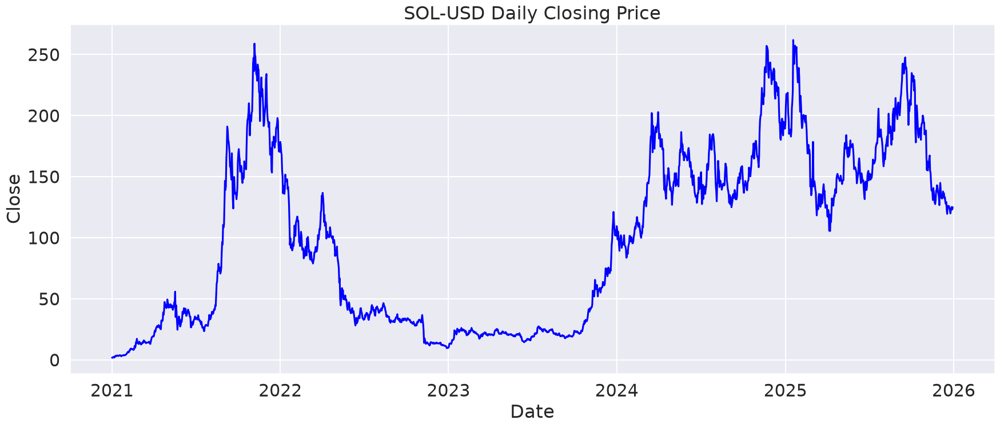

In [1306]:
# CHANGE CONTEXT TO poster TO INCREASE FONT SIZES
sns.set_context("talk", font_scale=1.3)

# PLOT OUT BTC-USD'S CLOSING PRICES SINCE 2014
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(18,8))
    sns.lineplot(x=df.index, y=df.Close, color='blue')
    ax.set_title('SOL-USD Daily Closing Price')    

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(directory_to_img, 'close.png'), 
            #dpi=300, bbox_inches='tight');

In [1308]:
# CALCULATE PRICE RETURNS AS DAILY PERCENTAGE CHANGE USING pct_change()
df['returns'] = 100 * df.Close.pct_change().dropna()

For practicality purposes, it's generally preferable to use the log returns especially in mathematic modeling, because it helps eliminate non-stationary properties of time series data, and makes it more stable:


LOG RETURNS FORMULA:

$r_{t, t+i} = log(P_{t+i} / P_{t})$

There's another advantage to log returns, which is that they're additive across time: $r_{t1, t2} + r_{t2, t3} = r_{t1, t3}$


In [1311]:
# CALCULATE LOG RETURNS BASED ON ABOVE FORMULA
df['log_returns'] = np.log(df.Close/df.Close.shift(1))

In [1312]:
df.index = df.index.date
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,returns,log_returns
2021-01-01,1.509775,1.859656,1.502038,1.842084,25722549,0.0,0.0,NaN,NaN
2021-01-02,1.845586,1.989295,1.721482,1.799275,31671064,0.0,0.0,-2.323944,-0.023514
2021-01-03,1.799902,2.364981,1.799902,2.161752,55073422,0.0,0.0,20.145722,0.183535
2021-01-04,2.162412,2.485097,1.876342,2.485097,59955405,0.0,0.0,14.957541,0.139393
2021-01-05,2.490982,2.502616,2.077742,2.157217,50555207,0.0,0.0,-13.193848,-0.141493


In [1313]:
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,returns,log_returns
2021-01-01,1.509775,1.859656,1.502038,1.842084,25722549,0.0,0.0,NaN,NaN
2021-01-02,1.845586,1.989295,1.721482,1.799275,31671064,0.0,0.0,-2.323944,-0.023514
2021-01-03,1.799902,2.364981,1.799902,2.161752,55073422,0.0,0.0,20.145722,0.183535
2021-01-04,2.162412,2.485097,1.876342,2.485097,59955405,0.0,0.0,14.957541,0.139393
2021-01-05,2.490982,2.502616,2.077742,2.157217,50555207,0.0,0.0,-13.193848,-0.141493


In [1314]:
# DROPPING THE 1ST ROW OF DATA 
# BECAUSE I SHIFTED IT FORWARD TO CALCULATE RETURNS/LOG RETURNS
df.dropna(inplace=True)

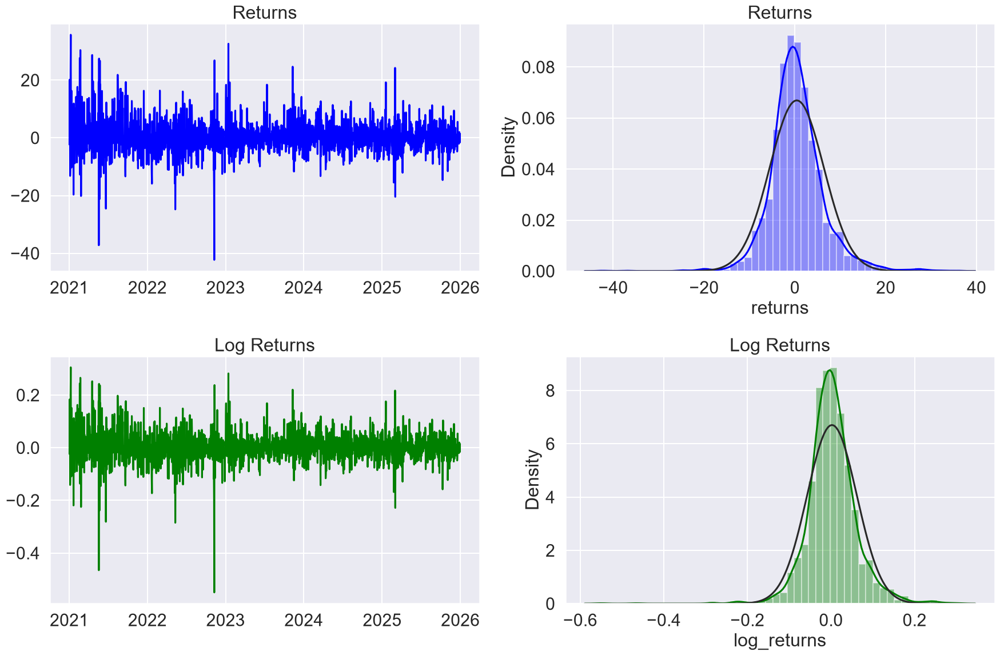

In [1315]:
# PLOT DISTRIBUTION PLOTS OF RETURNS & LOG RETURNS
# AND VISUALLY COMPARE THEM WITH THE STANDARD NORMAL DISTRIBUTION
with sns.axes_style("darkgrid"):
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18,12))

    axes[0][0].plot(df.returns, color='blue')
    axes[0][0].set_title('Returns')

    sns.distplot(df.returns, norm_hist=True, fit=stats.norm, color='blue',
                bins=50, ax=axes[0][1])
    axes[0][1].set_title('Returns')

    axes[1][0].plot(df.log_returns, color='green')
    axes[1][0].set_title('Log Returns')

    sns.distplot(df.log_returns, norm_hist=True, fit=stats.norm, color='green',
                bins=50, ax=axes[1][1])
    axes[1][1].set_title('Log Returns')
    plt.tight_layout()
   # plt.savefig(os.path.join(directory_to_img, 'returns_logreturns.png'), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

Both Returns & Log Returns show some:
- slight negative skewness
- positive kurtosis (leptokurtic) - higher peak with thicker tails than the standard normal distribution.


In [1317]:
df.returns.describe()

count    1824.000000
mean        0.408127
std         5.961054
min       -42.280904
25%        -2.893164
50%        -0.021940
75%         3.203225
max        35.703035
Name: returns, dtype: float64

In [1318]:
df.log_returns.describe()

count    1824.000000
mean        0.002312
std         0.059514
min        -0.549582
25%        -0.029358
50%        -0.000219
75%         0.031530
max         0.305299
Name: log_returns, dtype: float64

(Source: https://www.investopedia.com/articles/investing/102715/computing-historical-volatility-excel.asp)

The standard deviation will be different for log returns computed over longer or shorter intervals. For this specific project, the volatility would be for a certain fixed interval window (`INTERVAL_WINDOW`) is the standard deviation of log returns, or the square root of the sum of squares of log returns:

$\sigma_{interval} = \sqrt{\sum_{t} r_{t-1, t}^2}$

And then to scale the daily volatility by a certain frequency (weekly, monthly, yearly), we can multiply the daily volatility by the square root of that frequency in terms of day divided by the interval minus 1 (`INTERVAL_WINDOW - 1`). For example:

$\sigma_{daily} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{1}{interval-1}}$

$\sigma_{annualized} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{365}{interval-1}}$

$\sigma_{monthly} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{30}{interval-1}}$

$\sigma_{weekly} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{7}{interval-1}}$


In [1321]:
# CREATE A FUNCTION THAT CALCULATE REALIZED VOLATILITY
# FROM SAILY LOG RETURNS
def realized_volatility_daily(series_log_return):
    """
    Get the daily realized volatility which is calculated as the square root
    of sum of squares of log returns within a specific window interval 
    """
    n = len(series_log_return)
    return np.sqrt(np.sum(series_log_return**2)/(n - 1))

### Interval Window Selection

For this specific project I'll use an **interval window of 30 days** (equivalent to roughly 1 month of trading for cryptocurrencies). The goal here is to **forecast the average realized volatility of the next `n_future` 7 days** using all previous available datapoint with GARCH models (expanding window forecasting), and using a number of immediate past/historical datapoints (`n_past`) with Neural Networks (sliding window forecasting). 


In [1323]:
intervals = [7, 30, 60, 180, 365]
vols_df = {}

# ITERATE OVER intervals LIST
for i in intervals:
    # GET DAILY LOG RETURNS USING THAT INTERVAL
    vols = df.log_returns.rolling(window=i)\
                         .apply(realized_volatility_daily).values

    vols_df[i] = vols

# CONVERT vols_df FROM DICTIONARY TO PANDAS DATAFRAME
vols_df = pd.DataFrame(vols_df, columns=intervals, index=df.index)

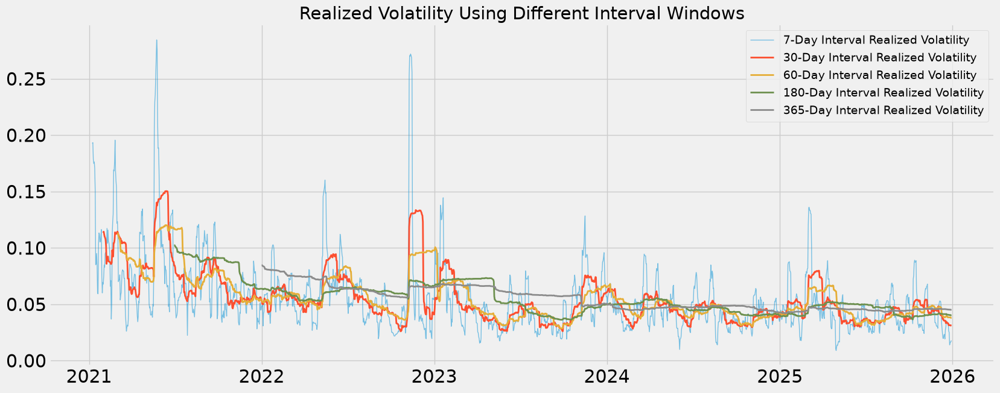

In [1324]:
# CHANGING MATPLOTLIB STYLE
plt.style.use(['fivethirtyeight'])

fig, ax = plt.subplots(figsize=(18,7))

for i in intervals:
    if i == 7:
        alpha = 0.5
        lw = 1
    else:
        alpha = 1.0
        lw = 2
    ax.plot(vols_df[i], label=f'{i}-Day Interval Realized Volatility', 
            alpha=alpha, lw=lw)

ax.set_title('Realized Volatility Using Different Interval Windows', fontsize=21)

plt.legend(loc='best', prop={'size': 14})
#plt.savefig(os.path.join(directory_to_img, 'diff_intervals.png'), 
 #           dpi=300, bbox_inches='tight')
plt.show();

The reason I selected 30 days is because 7 days seems too noisy to observe meaningful patterns, while longer intervals seem to smooth the volatility down significantly and tend to revert back to the mean.

Using interval window of 30 days would also help avoid wasting too many datapoints at the beginning of the dataset.

Time-series forecasting models are the models that are capable to predict **future** values based on previously observed values. Target "**future**" data in this case is obtained by **shifting the current volatility backward** by the number of `n_future` lags. 

For example, respected to last week's Monday, this week's Monday is the "**future**"; therefore I just need to shift the volatility this week back by 7 days, and use it as the desired "**future**" output for last week's, which I would then use for Neural Networks training and model performance evaluation. 

In [1326]:
INTERVAL_WINDOW = 30
n_future = 7

# GET BACKWARD LOOKING REALIZED VOLATILITY
df['vol_current'] = df.log_returns.rolling(window=INTERVAL_WINDOW)\
                                   .apply(realized_volatility_daily)

# GET FORWARD LOOKING REALIZED VOLATILITY 
df['vol_future'] = df.log_returns.shift(-n_future)\
                                 .rolling(window=INTERVAL_WINDOW)\
                                 .apply(realized_volatility_daily)

In [1327]:
df.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,returns,log_returns,vol_current,vol_future
count,1824.000000,1824.000000,1824.000000,1824.000000,1.824000e+03,1824.0,1824.0,1824.000000,1824.000000,1795.000000,1788.000000
mean,98.550725,102.221179,94.893207,98.601344,2.604108e+09,0.0,0.0,0.408127,0.002312,0.055124,0.054911
std,71.598726,73.906837,69.127701,71.544286,2.750630e+09,0.0,0.0,5.961054,0.059514,0.023342,0.023136
min,1.799902,1.989295,1.721482,1.799275,2.790447e+07,0.0,0.0,-42.280904,-0.549582,0.025925,0.025925
25%,27.297947,28.707379,25.859532,27.382167,6.176276e+08,0.0,0.0,-2.893164,-0.029358,0.039744,0.039701
50%,97.859879,101.650822,94.051613,97.941837,1.864709e+09,0.0,0.0,-0.021940,-0.000219,0.049416,0.049368
75%,157.075966,162.790485,150.879875,157.006351,3.534494e+09,0.0,0.0,3.203225,0.031530,0.062067,0.061971
max,261.872437,294.334961,253.187439,261.869751,3.317296e+10,0.0,0.0,35.703035,0.305299,0.150297,0.150297


The 2 columns `Dividends` and `Stock Splits` don't store any information, all rows are `0.0`, so I'll remove them.

In [1329]:
df = df.drop(['Dividends', 'Stock Splits'], axis=1)

In [1330]:
df.describe()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future
count,1824.000000,1824.000000,1824.000000,1824.000000,1.824000e+03,1824.000000,1824.000000,1795.000000,1788.000000
mean,98.550725,102.221179,94.893207,98.601344,2.604108e+09,0.408127,0.002312,0.055124,0.054911
std,71.598726,73.906837,69.127701,71.544286,2.750630e+09,5.961054,0.059514,0.023342,0.023136
min,1.799902,1.989295,1.721482,1.799275,2.790447e+07,-42.280904,-0.549582,0.025925,0.025925
25%,27.297947,28.707379,25.859532,27.382167,6.176276e+08,-2.893164,-0.029358,0.039744,0.039701
50%,97.859879,101.650822,94.051613,97.941837,1.864709e+09,-0.021940,-0.000219,0.049416,0.049368
75%,157.075966,162.790485,150.879875,157.006351,3.534494e+09,3.203225,0.031530,0.062067,0.061971
max,261.872437,294.334961,253.187439,261.869751,3.317296e+10,35.703035,0.305299,0.150297,0.150297


Since I am currently using an `INTERVAL_WINDOW` of 30 and a horizon `n_future` of  7, the volatilty of first 30 values as well as the last 7 values of the dataframe would be `NaN`, and therefore need to be dropped from the dataset.

In [1332]:
# DROPPING ALL NaN VALUES
df.dropna(inplace=True)

## **Exploratory Data Analysis**

First I would just plot out my desired target outputs `vol_future` with respect to the current volatility `vol_current`. The first plot shows all the datapoints I have available that covers 7 years, but then the second plot is only zooming in the most recent 365 days.

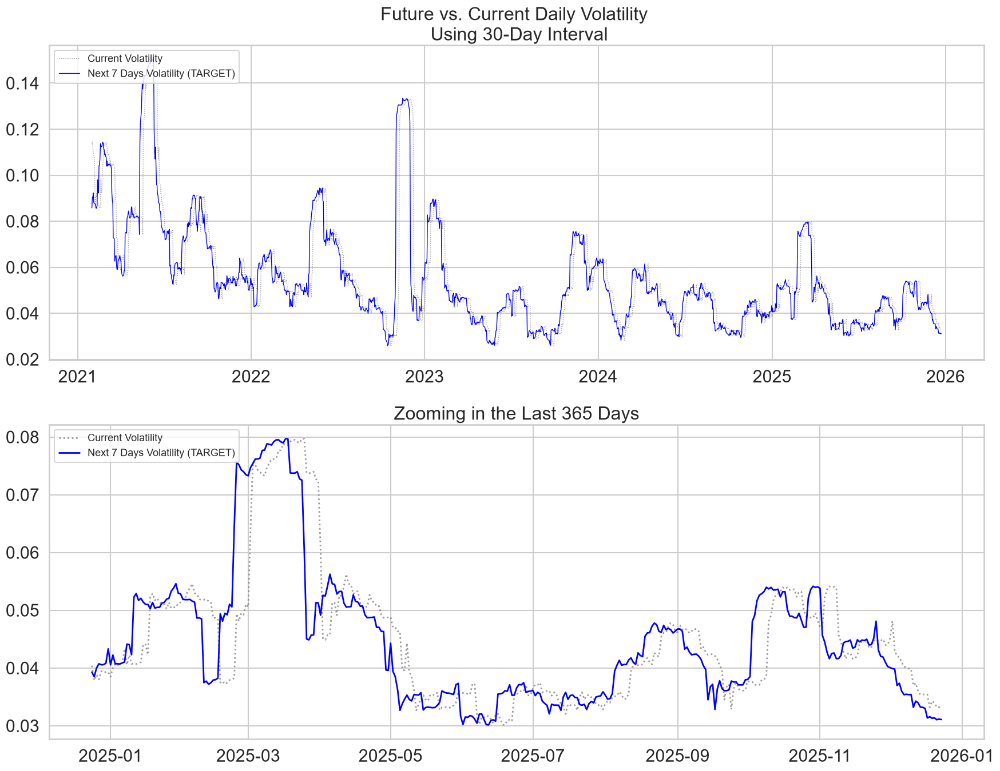

In [1335]:
n_zoom = 365
sns.set_context("talk", font_scale=1.3)
# plt.style.use(['seaborn'])

# VISUALIZE REALIZED CURRENT VS. FUTURE VOLATILITY
with sns.axes_style("whitegrid"):
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(18,14))

    ax1.plot(df.vol_current, alpha=.8, lw=1, color='gray', ls=':',
            label='Current Volatility')
    ax1.plot(df.vol_future, lw=1, color='blue',
            label=f'Next {n_future} Days Volatility (TARGET)')

    ax2.plot(df.vol_current[-n_zoom:], alpha=.8, lw=2, color='gray', ls=':',
            label='Current Volatility')
    ax2.plot(df.vol_future[-n_zoom:], lw=2, color='blue',
            label=f'Next {n_future} Days Volatility (TARGET)')

    ax1.title.set_text(f'Future vs. Current Daily Volatility \n Using {INTERVAL_WINDOW}-Day Interval')
    ax2.title.set_text(f'Zooming in the Last {n_zoom} Days')

    ax1.legend(loc='upper left', prop={'size': 13}, frameon=True)
    ax2.legend(loc='upper left', prop={'size': 13}, frameon=True)
    plt.tight_layout()
    #plt.savefig(os.path.join(directory_to_img, 'daily_vol.jpg'), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

In the plot above, the **blue line** indicates the **target future** value that I ultimately try to match up to. 

And the dotted **gray line** represents the **current volatility** in real-time. 

This is a visualization of how current volatility is shifted backward to become future values, which I want to eventually aim for. 

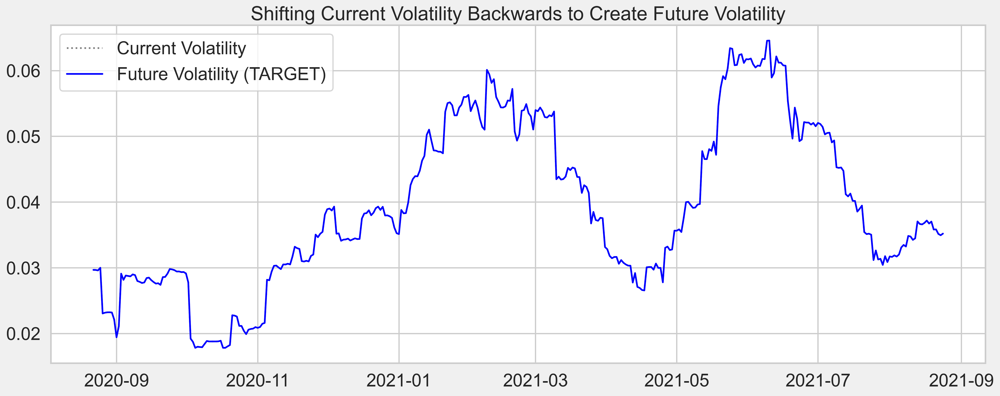

### **Daily Volatility Grouped by Month**

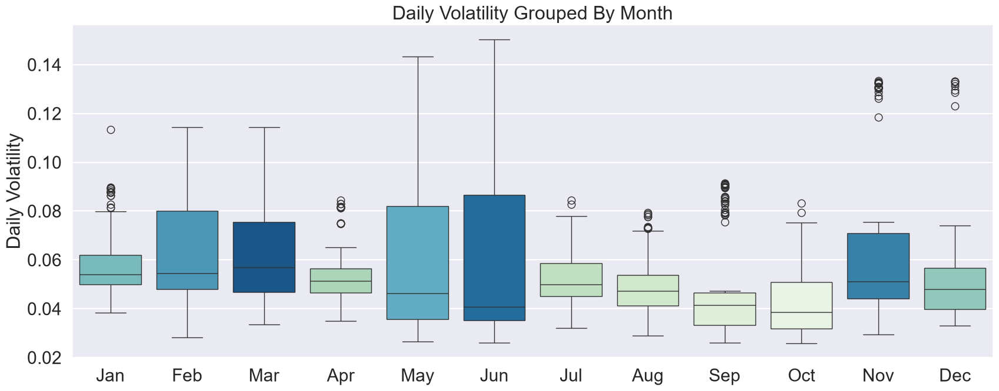

In [1338]:
# PRESORT MONTHS IN CHRONOLOGICAL ORDER 
ordered_months = ['Jan', 'Feb', 'Mar', 'Apr','May','Jun', 
                  'Jul', 'Aug','Sep', 'Oct', 'Nov', 'Dec']

# Convert index to DatetimeIndex
df.index = pd.to_datetime(df.index)

# GROUP vol_current BY MONTH AND TAKE THE MEAN
data = df.groupby(by=[df.index.month_name()]).vol_current.mean()

# ABBREVIATE MONTH NAME
data.index = [x[:3] for x in data.index]

# SELECT PALETTE
pal = sns.color_palette("GnBu", len(data))

# SORT MONTH BY AVERAGE vol_current
rank = data.argsort().argsort().reindex(ordered_months)

with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(18,7))
    
    sns.boxplot(x=[x[:3] for x in df.index.month_name()], 
                y=df.vol_current, 
                palette=np.array(pal)[rank],
                order=ordered_months)
    ax.set(xlabel='', 
           ylabel='Daily Volatility', 
           title='Daily Volatility Grouped By Month')
    #plt.savefig(os.path.join(directory_to_img, "vol_by_month.png"), 
     #           dpi=300, bbox_inches='tight')
    plt.show()

In [1339]:
df.vol_current.sort_values(ascending=False)[:50]

2021-06-13    0.150297
2021-06-14    0.150263
2021-06-11    0.150178
2021-06-16    0.150052
2021-06-12    0.150051
2021-06-15    0.149910
2021-06-08    0.148681
2021-06-09    0.148575
2021-06-10    0.148465
2021-06-07    0.147993
2021-06-06    0.147156
2021-06-05    0.146643
2021-06-17    0.146442
2021-06-04    0.146398
2021-06-03    0.146357
2021-06-02    0.144290
2021-05-30    0.143447
2021-06-01    0.143336
2021-05-31    0.143294
2021-05-29    0.143232
2021-05-28    0.143167
2021-05-27    0.140757
2021-05-26    0.140399
2021-05-24    0.140122
2021-05-25    0.137517
2021-05-23    0.134256
2022-11-23    0.133490
2022-12-01    0.133218
2022-12-03    0.133100
2022-12-02    0.132979
2022-11-30    0.132961
2022-11-25    0.132655
2022-11-26    0.132603
2022-11-28    0.132594
2022-11-29    0.132593
2022-11-24    0.132500
2022-11-27    0.132315
2022-12-04    0.132147
2022-12-05    0.131217
2022-11-22    0.130958
2022-11-21    0.130901
2022-11-20    0.130752
2022-11-15    0.130599
2022-11-14 

## Daily Volatility Grouped by Month
From the monthly distribution and top volatility dates, it can be observed that:
- Volatility has historically reached its highest peaks during **May–June** (driven by the 2021 crypto market crash) and **November–December** (driven by the November 2022 FTX collapse, which heavily impacted Solana).
- **March and April** display a high concentration of upward outliers.
- **August and September** have historically been comparatively calmer regimes, while the final test window (**late November to December 2025**) falls into a historically active year-end per
  iod.

## Daily Volatility Grouped byWe can observe these major ecosystem events reflected in the yearly distributions above 
- Solana's explosive breakout in 2021 (surging from under $2 in January to over $250 in November) alongside intense summer market drawdowns produced the highest median and peak daily realized volatility (~0.15). 
-In 2022, severe market dislocations from the Terra/LUNA collapse in May and the FTX contagion in November–December triggered sharp volatility spikes above 0.13.
-From 2023 through 2025, deeper institutional liquidity and maturing SOL perpetuals and options markets helped moderate baseline daily volatility, though sharp episodic spikes still occurred during major market rallies and macro events.ill occur.

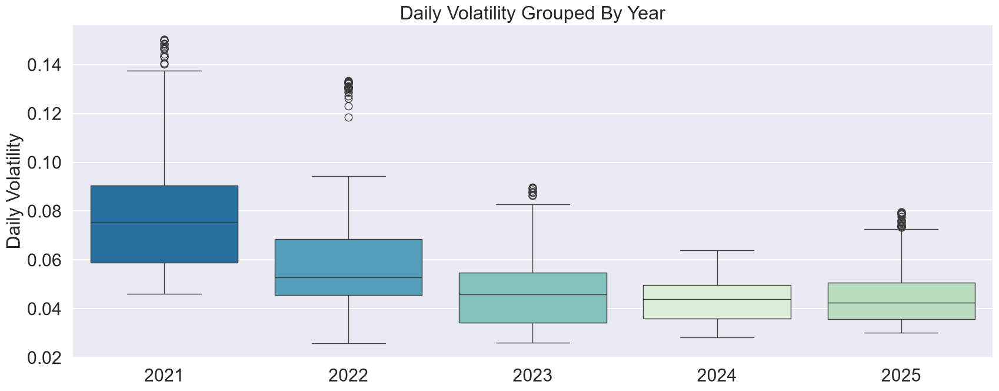

In [1342]:
# GROUP vol_current BY YEAR AND TAKE THE MEAN
data = df.groupby(by=[df.index.year]).vol_current.mean()

# SELECT PALETTE
pal = sns.color_palette("GnBu", len(data))

# SORT MONTH BY AVERAGE vol_current
rank = data.argsort().argsort()

with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(18,7))
    
    sns.boxplot(x=df.index.year, 
                y=df.vol_current, 
                palette=np.array(pal)[rank])
    ax.set(xlabel='', 
           ylabel='Daily Volatility', 
           title='Daily Volatility Grouped By Year')
    #plt.savefig(os.path.join(directory_to_img, "vol_by_year.png"), 
   #             dpi=300, bbox_inches='tight')
    plt.show()

Cryptocurrencies have gone through some huge structural changes in the last few years that would've affected volatility directly, such as:
- Crypto Options became available on Deribit in 2016
- Bitcoin Futures was offered on CME in 2017
- and then CME Bitcoin Options in 2020

These events have allowed people to trade crypto volatility more efficiently, and therefore data pre-2016 are likely structurally different, and probably followed different patterns compared to data after 2016.

We can these big events being reflected in the plot above - Bitcoin's first record peak in 2017 (around USD 19,800 towards the end of December). And the outliers in 2020 corresponded with its over 200% surge in 2020 (Bitcoin started at USD 7,200 at the beginning of 2020). It reached USD 20,000 on most exchanges on 12/15/2020, and then proceeded to hit USD 30,000 just 17 days later, which is no small feat. To put things in perspective, it took the Dow Jones close to 3 years to make the same move. And then, on 01/07/2021 it broke USD 40,000. As of the time this report is written, BTC-USD is traded at high USD 49,700.

It can be observed that 2021's daily volatiliy overall has also been on the higher side. 

### **Daily Volatility Distribution**

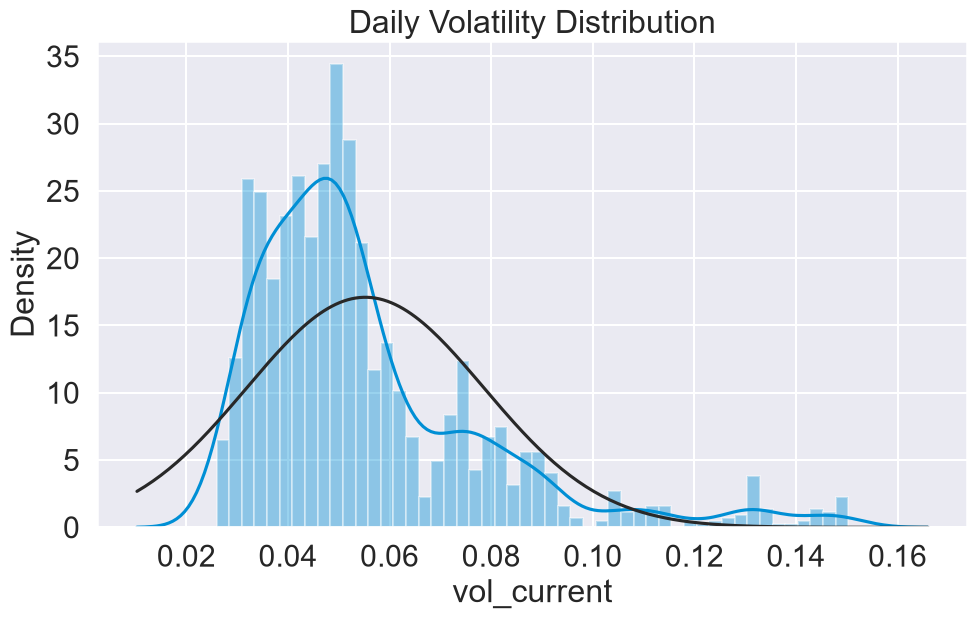

In [1347]:
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(10,6))
    sns.distplot(df.vol_current, norm_hist=True, fit=stats.norm,
                bins=50, ax=ax)
    plt.title('Daily Volatility Distribution')
   # plt.savefig(os.path.join(directory_to_img, "vol_dist.png"), 
    #            dpi=300, bbox_inches='tight')
    plt.show();

The distribution of daily realized volatility is lightly right skewed, with a small number of larger values spreaded thinly on the right.

A skewed right distribution would have smaller median compared to mean, and mode smaller than median (mode < median < mean).

### **Returns/Log Returns Stationarity Checking**



In [1350]:
from statsmodels.tsa.stattools import adfuller

In [1351]:
# LOG RETURNS
adfuller_results = adfuller(df.log_returns.dropna())

print(f'ADF Statistic: {adfuller_results[0]}')
print(f'p-value: {adfuller_results[1]}')
print('Critical Values:')
for key, value in adfuller_results[4].items():
    print(f'{key}: {value:.4f}')

ADF Statistic: -14.444460933149983
p-value: 7.268330091307242e-27
Critical Values:
1%: -3.4340
5%: -2.8632
10%: -2.5676


In [1352]:
# RETURNS
adfuller_results = adfuller(df.returns.dropna())

print(f'ADF Statistic: {adfuller_results[0]}')
print(f'p-value: {adfuller_results[1]}')
print('Critical Values:')
for key, value in adfuller_results[4].items():
    print(f'{key}: {value:.4f}')

ADF Statistic: -14.401520591253314
p-value: 8.493079095123871e-27
Critical Values:
1%: -3.4340
5%: -2.8632
10%: -2.5676


Using a significant level alpha of 0.05, `p-value` for both Returns and Log Returns are significantly smaller than alpha, which means there's enough evidence to reject the Null Hypothesis. 

--> Returns and Log returns are both not dependent on time/trend

## Train-Validation-Test Splits
After computing the 30-day rolling realized volatility and shifting forward by 7 days, there are **1,788 usable daily datapoints** spanning **January 31, 2021 to December 23, 2025**. Because cryptocurrency markets trade 24/7, a full calendar year consists of 365 trading days rather than the 252 days used in traditional equity markets.

I split the dataset chronologically into three subsets:
- **Test Set (30 days — ~1.7%):** `2025-11-24` to `2025-12-23` for final out-of-sample evaluation.
- **Validation Set (365 days — ~20.4%):** `2024-11-24` to `2025-11-23` for hyperparameter tuning and model selection.
- **Training Set (1,393 days — ~77.9%):** `2021-01-31` to `2024-11-23` for model fitting.

In [1355]:
# PRE-DETERMINE DESIRED TEST & VALIDATION SIZES
test_size = 30
val_size = 365

# CONVERT TO INDICES
split_time_1 = len(df) - (val_size + test_size)
split_time_2 = len(df) - test_size

# GET CORRESPONDING DATETIME INDICES FOR EACH SET
train_idx = df.index[:split_time_1]
val_idx = df.index[split_time_1:split_time_2]
test_idx = df.index[split_time_2:]

In [1356]:
print(f'TRAINING \tFrom: {train_idx[0]} \tto: {train_idx[-1]} \t{len(train_idx)} days')
print(f'VALIDATION \tFrom: {val_idx[0]} \tto: {val_idx[-1]} \t{len(val_idx)} days')
print(f'TEST \t\tFrom: {test_idx[0]} \tto: {test_idx[-1]} \t{len(test_idx)} days')

TRAINING 	From: 2021-01-31 00:00:00 	to: 2024-11-23 00:00:00 	1393 days
VALIDATION 	From: 2024-11-24 00:00:00 	to: 2025-11-23 00:00:00 	365 days
TEST 		From: 2025-11-24 00:00:00 	to: 2025-12-23 00:00:00 	30 days


The target here would be `vol_future` which represents the daily realized volatility of the next `n_future` days from today (average daily volatility from `t + n_future - INTERVAL_WINDOW` to time step `t + n_future`). 

For example, using an `n_future` value of 7 and an `INTERVAL_WINDOW` of 30, the value that I want to predict at time step `t` would be the average daily realized volatility from time step `t-22` to time step `t+7`.

In [1358]:
# SPLIT FORWARD VOLATILITY INTO 3 PARTS 
# (this would be the target)
y_train = df.vol_future[train_idx]
y_val = df.vol_future[val_idx]
y_test = df.vol_future[test_idx]

In [1359]:
# SPLIT CURRENT DAILY REALIZED VOLATILITY INTO 3 PARTS 
# (this would be the input for baseline, random walk, and NN models)
x_train = df.vol_current[train_idx]
x_val = df.vol_current[val_idx]
x_test = df.vol_current[test_idx]

In [1360]:
# SPLIT RETURNS INTO 3 PARTS
# (this would be the input for GARCH models)
r_train = df.returns[train_idx]
r_val = df.returns[val_idx]
r_test = df.returns[test_idx]

In [1361]:
# SPLIT LOG RETURNS INTO 3 PARTS
# (mostly for visualization)
lr_train = df.log_returns[train_idx]
lr_val = df.log_returns[val_idx]
lr_test = df.log_returns[test_idx]

In [1362]:
y_train.describe()

count    1393.000000
mean        0.057891
std         0.024711
min         0.025925
25%         0.041961
50%         0.051191
75%         0.068432
max         0.150297
Name: vol_future, dtype: float64

In [1363]:
x_train.describe()

count    1393.000000
mean        0.058218
std         0.024963
min         0.025925
25%         0.041961
50%         0.051285
75%         0.069285
max         0.150297
Name: vol_current, dtype: float64

## **Data Preprocessing**

### 1. Feature Normalization

As I am going to build various types of models based on different algorithms using different types of inputs, it would be better to normalize the volatilities to standardize the predictions generated by different models. After experimenting with different Scalers, I decided to use `MinMaxScaler` as it yielded best results overall.

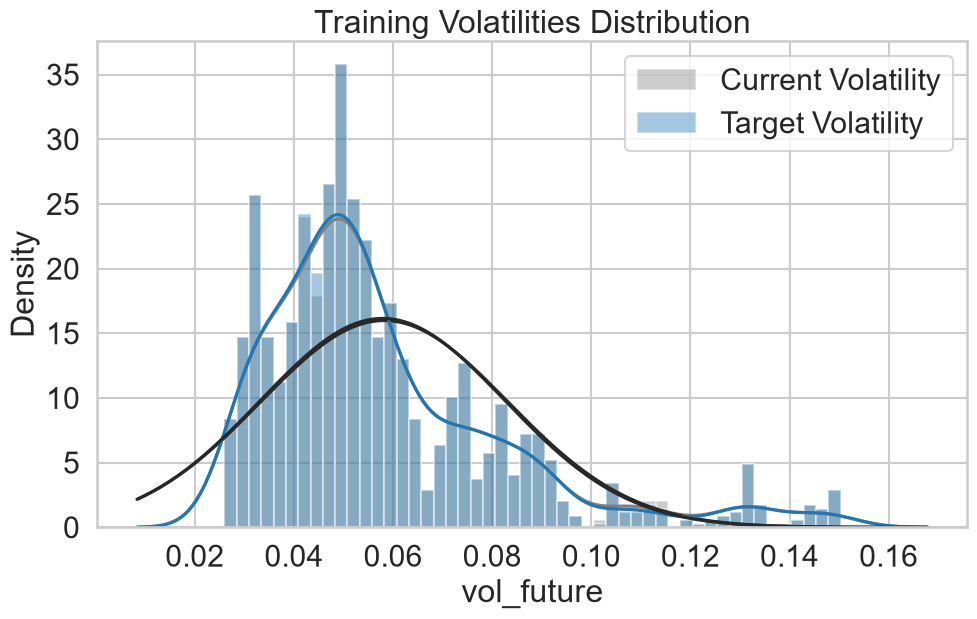

In [1365]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10,6))
    sns.distplot(x_train, norm_hist=True, fit=stats.norm, 
                 color='gray', 
                 bins=50, ax=ax, label='Current Volatility')
    sns.distplot(y_train, norm_hist=True, fit=stats.norm,
                 color='tab:blue', 
                 bins=50, ax=ax, label='Target Volatility')
    plt.title('Training Volatilities Distribution')
    plt.legend()
    #plt.savefig(os.path.join(directory_to_img, "vol_dist.png"), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

In [1366]:
def transform_volatility_to_scaler(scaler, tf_series):
    '''
    Transform a series to a fitted scaler
    '''
    idx = tf_series.index
    output = pd.Series(scaler.transform(tf_series.values.reshape(-1,1))[:,0],
                       index=idx)
    return output

In [1367]:
# INITIATE SCALER
scaler_vol = MinMaxScaler()

# FIT SCALER TO CURRENT VOLATILITY IN TRAINING SET
scaler_vol = scaler_vol.fit(x_train.values.reshape(-1,1))

In [1368]:
# TRANSFORM TRAINING CURRENT & FUTURE VOLATILITIES 
x_train_scaled = transform_volatility_to_scaler(scaler_vol, x_train)
y_train_scaled = transform_volatility_to_scaler(scaler_vol, y_train)

# TRANSFORMING VALIDATION CURRENT & FUTURE VOLATILITIES
x_val_scaled = transform_volatility_to_scaler(scaler_vol, x_val)
y_val_scaled = transform_volatility_to_scaler(scaler_vol, y_val)

# TRANSFORMING TEST CURRENT & FUTURE VOLATILITIES
x_test_scaled = transform_volatility_to_scaler(scaler_vol, x_test)
y_test_scaled = transform_volatility_to_scaler(scaler_vol, y_test)

In [1369]:
x_train.head(10)

2021-01-31    0.113470
2021-02-01    0.114315
2021-02-02    0.111876
2021-02-03    0.109893
2021-02-04    0.108899
2021-02-05    0.107150
2021-02-06    0.101388
2021-02-07    0.085780
2021-02-08    0.090459
2021-02-09    0.090367
Name: vol_current, dtype: float64

In [1370]:
y_train.head(10)

2021-01-31    0.085780
2021-02-01    0.090459
2021-02-02    0.090367
2021-02-03    0.092310
2021-02-04    0.088018
2021-02-05    0.087867
2021-02-06    0.087564
2021-02-07    0.087550
2021-02-08    0.086905
2021-02-09    0.085680
Name: vol_future, dtype: float64

In [1371]:
x_train_scaled.head(10)

2021-01-31    0.703895
2021-02-01    0.710691
2021-02-02    0.691078
2021-02-03    0.675133
2021-02-04    0.667138
2021-02-05    0.653078
2021-02-06    0.606753
2021-02-07    0.481253
2021-02-08    0.518876
2021-02-09    0.518134
dtype: float64

In [1372]:
y_train_scaled.head(10)

2021-01-31    0.481253
2021-02-01    0.518876
2021-02-02    0.518134
2021-02-03    0.533763
2021-02-04    0.499250
2021-02-05    0.498036
2021-02-06    0.495603
2021-02-07    0.495487
2021-02-08    0.490299
2021-02-09    0.480450
dtype: float64

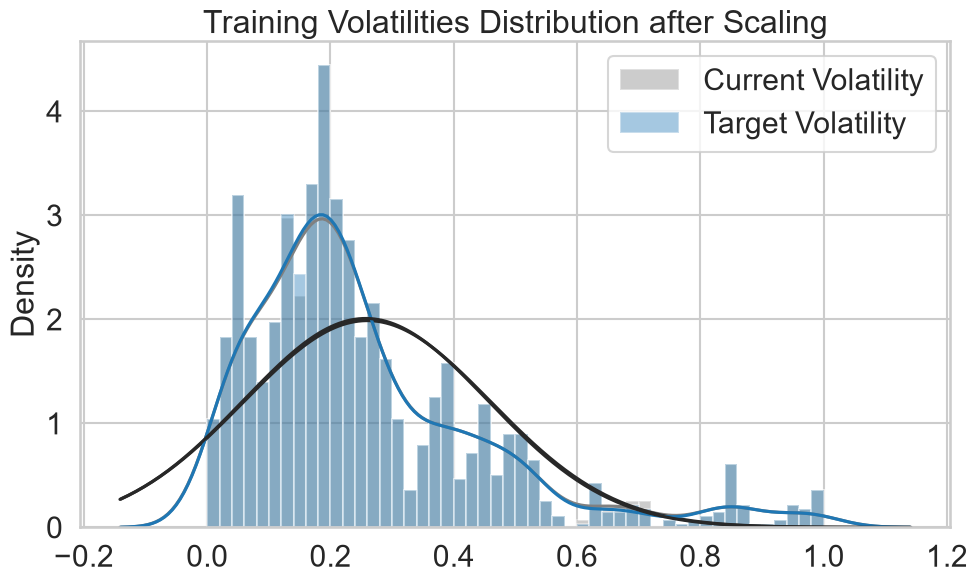

In [1373]:
# PLOTTING VOLATILITIES AFTER SCALING
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10,6))
    sns.distplot(x_train_scaled, norm_hist=True, fit=stats.norm, 
                 color='gray', 
                 bins=50, ax=ax, label='Current Volatility')
    sns.distplot(y_train_scaled, norm_hist=True, fit=stats.norm,
                 color='tab:blue', 
                 bins=50, ax=ax, label='Target Volatility')
    plt.title('Training Volatilities Distribution after Scaling')
    plt.legend()
    #plt.savefig(os.path.join(directory_to_img, "vol_dist.png"), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

### 2. Train-Validation-Test Visualization

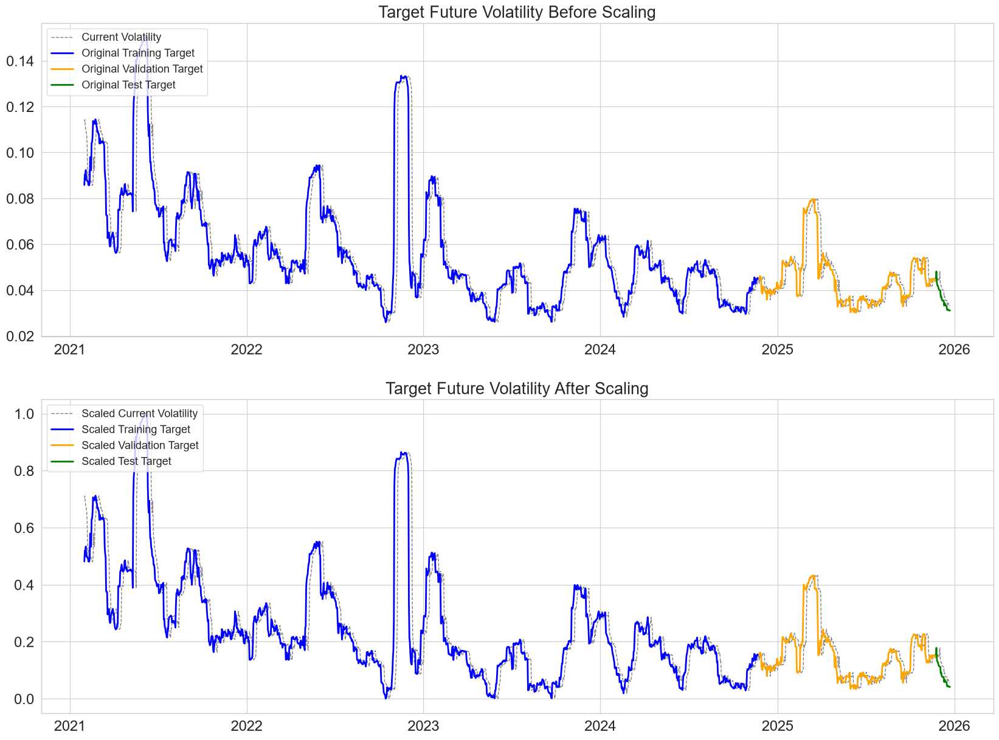

In [1381]:
sns.set_context("paper", font_scale=2)

# VISUALIZE TRAIN/VALIDATION/TEST vol_future BEFORE & AFTER TRAINING
with sns.axes_style("whitegrid"):
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(18,14))

    ax1.plot(df.vol_current, lw=1, color='gray', ls='--',
                label='Current Volatility')
    ax1.plot(y_train, color='blue', label='Original Training Target', lw=2)
    ax1.plot(y_val, color='orange', label='Original Validation Target', lw=2)
    ax1.plot(y_test, color='green', label='Original Test Target', lw=2)

    ax1.title.set_text('Target Future Volatility Before Scaling')

    ax2.plot(transform_volatility_to_scaler(scaler_vol, df.vol_current), 
                lw=1, color='gray', ls='--',
                label='Scaled Current Volatility')
    ax2.plot(y_train_scaled, color='blue', label='Scaled Training Target', lw=2)
    ax2.plot(y_val_scaled, color='orange', label='Scaled Validation Target', lw=2)
    ax2.plot(y_test_scaled, color='green', label='Scaled Test Target', lw=2)

    ax2.title.set_text('Target Future Volatility After Scaling')

    ax1.legend(loc='upper left', prop={'size': 13}, frameon=True)
    ax2.legend(loc='upper left', prop={'size': 13}, frameon=True)
    #plt.savefig(os.path.join(directory_to_img, 'train_val_test_org_scled.png'), 
   #             dpi=300, bbox_inches='tight')
    plt.show();

One of the most obvious difference between the 2 plots is the y-axis. After scaling, volatilities fall in the range of [0,1] instead of [0, 0.12] as before.

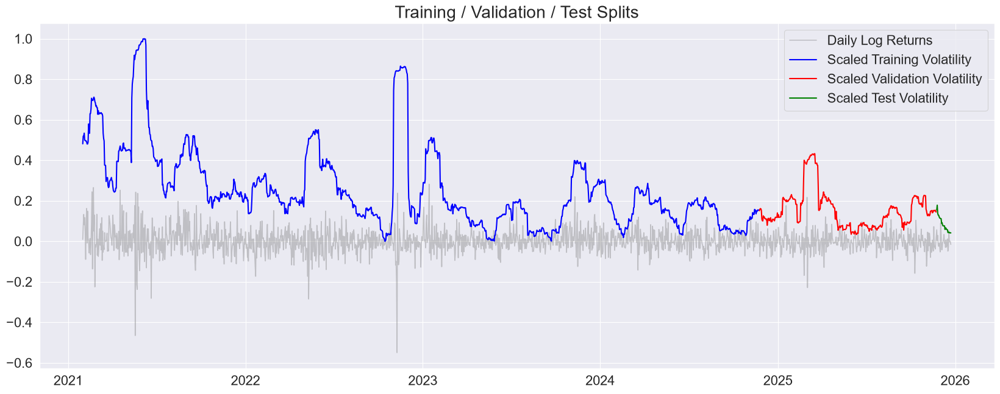

In [1414]:
sns.set_context("paper", font_scale=1.8)
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(18,7))

    plt.plot(df.log_returns, color='gray', label='Daily Log Returns', alpha=0.4)

    plt.plot(y_train_scaled, color='blue', 
             label='Scaled Training Volatility', lw=1.5)
    plt.plot(y_val_scaled, color='red', 
             label='Scaled Validation Volatility', lw=1.5)
    plt.plot(y_test_scaled, color='green', 
             label='Scaled Test Volatility', lw=1.5)

    plt.plot()
    plt.title('Training / Validation / Test Splits', fontsize=20)
    plt.legend(frameon=True)
   # plt.savefig(os.path.join(directory_to_img, 'train_val_test.png'), 
   #             dpi=300, bbox_inches='tight')
    plt.show();

# MODELING

## 1. Performance Metrics

Usually with financial time series, if we just shift through the historic data trying different methods, parameters and timescales, it's almost certain to find to some strategy with in-sample profitability at some point. However the whole purpose of "forecasting" is to predict the future based on currently available information, and a model that performs best on training data might not be the best when it comes to out-of-sample generalization (or **overfitting**). Avoiding/Minimizing overfitting is even more important in the constantly evolving financial markets where the stake is high.

The 2 main metrics I'd be using are **RMSPE (Root Mean Squared Percentage Error)** and **RMSE (Root Mean Square Errors)** with RMSPE prioritized. Timescaling is very important in the calculation of volatility due to the level of freedom in frequency/interval window selection. Therefore I think RMSPE would help capture degree of errors compared to desired target values better than other metrics. Also RMSPE would punish large errors more than regular MAPE (Mean Absolute Percentage Error), which is what I want to do here.

RMSE and RMSPE would be tracked across different models' performance on validation set forecasting to indicate their abilities to generalize on out-of-sample data.

In [1417]:
# DEFINE ROOT MEAN SQUARED PERCENTAGE ERROR FUNCTION
def RMSPE(y_true, y_pred):
    """
    Compute Root Mean Squared Percentage Error between 2 arrays
    """
    output = np.sqrt(np.mean(np.square((y_true - y_pred) / y_true)))
    return output

In [1419]:
# DEFINE ROOT MEAN SQUARED ERROR FUNCTION
def RMSE(y_true, y_pred):
    """
    Compute Root Mean Squared Error between 2 arrays
    """
    output = np.sqrt(mse(y_true, y_pred))
    return output

In [1421]:
# INITIATE A DATAFRAME FOR MODEL PERFORMANCE TRACKING & COMPARISON 
perf_df = pd.DataFrame(columns=['Model', 'Validation RMSPE', 'Validation RMSE'])

In [1422]:
# A FUNCTION THAT LOGS MODEL NAME, RMSE AND RMPSE INTO perf_df
# FOR EASY COMPARISON LATER
def log_perf(y_true, y_pred, model_name):
    perf_df.loc[len(perf_df.index)] = [model_name, 
                                       RMSPE(y_true, y_pred), 
                                       RMSE(y_true, y_pred)]
    return perf_df

In [1423]:
# PLOTTING MODEL PREDICTIONS VS. TARGET VALUES
def viz_model(y_true, y_pred, model_name):
    sns.set_context("paper", font_scale=1.7)
    plt.rcParams["axes.grid"] = False

    with sns.axes_style("whitegrid"):
        plt.figure(figsize=(18,7))
        plt.plot(x_val_scaled, color='gray',  ls=':',
                label=f"Scaled Current Daily Volatility")
        
        plt.plot(y_true, color='blue', lw=2, 
                label=f"Target Volatility")
        plt.plot(y_pred, color='orange', lw=2.5,
                label=f'Forecasted Volatility')
        
        plt.plot(lr_val, color='gray', alpha=0.4,
                 label='Daily Log Returns')

        plt.title(f'{model_name} \non Validation Data')
        plt.legend(loc='best', frameon=True)

## 2. Baseline Models

### 2.1. Mean Baseline

One of the essential characteristics of Volatility is it's **mean-revert** over the long term. Therfore my first baseline model his would be a very simple one that only outputs the average current realized volatility of the whole training set as predictions everything.

In [1425]:
# CALCULATE THE MEAN OF SCALED TRAINING DATA
mean_train_vol = x_train_scaled.mean()
mean_train_vol

0.25964870710955984

In [1426]:
# CREATE SERIES OF PREDICTIONS FOR BASELINE MODEL ON VALIDATION SET
baseline_preds = np.ones(len(val_idx)) * mean_train_vol
baseline_preds = pd.Series(baseline_preds, index=lr_val.index)

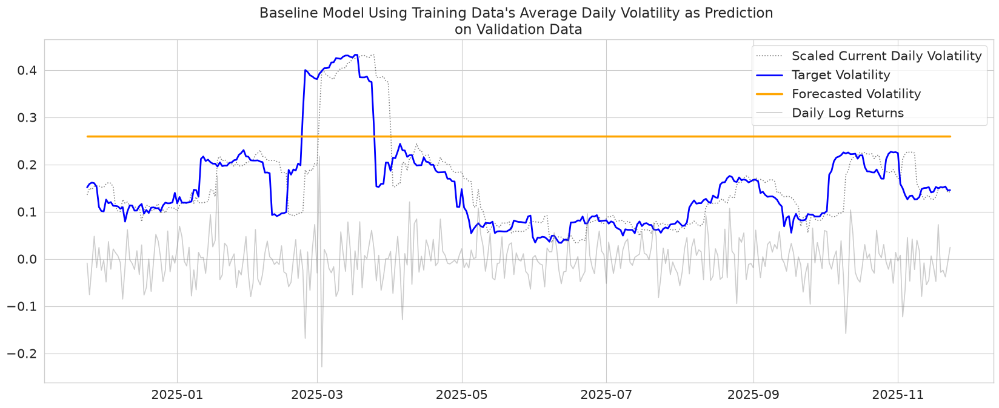

In [1427]:
viz_model(y_val_scaled, baseline_preds, 
          f"Baseline Model Using Training Data's Average Daily Volatility as Prediction")
#plt.savefig(os.path.join(directory_to_img, 'baseline.jpg'), dpi=300, bbox_inches='tight')
plt.show();

In [1428]:
log_perf(y_val_scaled, baseline_preds, 'Mean Baseline')

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248


### 2.2. Random Walk Naive Forecasting

A commonly known fact about volatility is that it tends to be **autocorrelated**, and **clusters** in the short-term. This property can be used to implement a naive model that just "predicts" future volatility by using whatever the daily volatility was at the immediate previous time step.

In this case, I'll use the average daily volatility of the most recent `INTERVAL_WINDOW` as predictions for the next 7 days, which is essentially using `vol_current` at time step `t` and prediction for `vol_future` at time step `t`.

In [1430]:
# USING THE PREVIOUS n_future DAY'S VOLATILITY
random_walk_preds = x_val_scaled

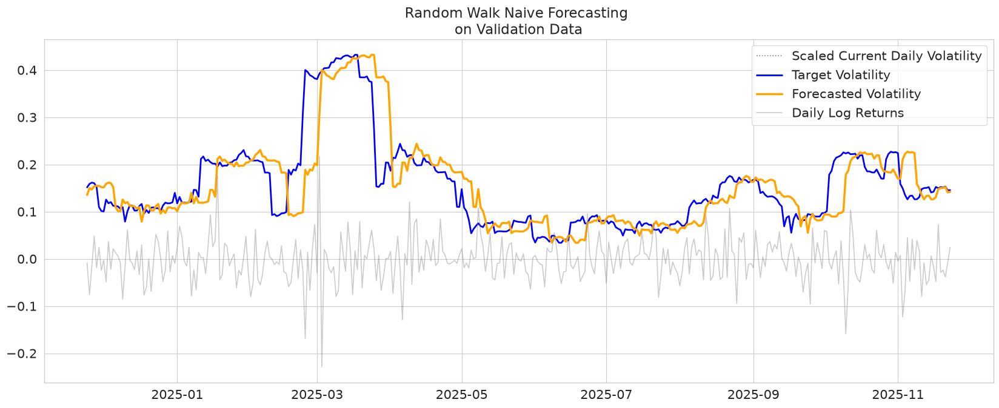

In [1431]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, random_walk_preds, 'Random Walk Naive Forecasting')
#plt.savefig(os.path.join(directory_to_img, 'naive.jpg'), 
 #           dpi=300, bbox_inches='tight')
plt.show();

In [1432]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, random_walk_preds, 
         'Random Walk Naive Forecasting')

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248
1,Random Walk Naive Forecasting,0.399399,0.056232


So the both error mertrics have gone down by a decent amount. Naive forecasting in time series is sometimes surprisingly difficult to outperform.

## 3. GARCH Models

(Reference: http://users.metu.edu.tr/ozancan/ARCHGARCHTutorial.html)

GARCH stands for **Generalized Autoregressive Conditional Heteroskedasticity**, which is an extension of the ARCH model (Autoregressive Conditional Heteroskedasticity). 

GARCH includes lag variance terms with lag residual errors from a mean process, and is the traditional econometric approach to volatility prediction of financial time series.

Mathematically, GARCH can be represented as follows:

\begin{align*}
\sigma_{t}^2 = \omega + \sum_{i}^{q}\alpha_{i}\epsilon_{t-i}^2 + \sum_{1}^{p}\beta_{i}\sigma_{t-i}^2
\end{align*}

in which $\sigma_{t}^2$ is variance at time step `t` and $\epsilon_{t-i}^2$ is the model residuals at time step `t-1`

GARCH(1,1) only contains first-order lagged terms and the mathematic equation for it is: 

\begin{align*}
\sigma^2_t = \omega + \alpha\epsilon^{2}_{(t-1)} + \beta\sigma^{2}_{(t-1)}
\end{align*}

where $\alpha$, $\beta$ and $\omega$ sum up to 1, and $\omega$ is the long term variance.


(Reference: **Positional Option Trading** - Euan Sinclair)

GARCH is generally regarded as an insightful improvement on naively assuming future volatility will be like the past, but also considered widely overrated as predictor by some experts in the field of volatility. GARCH models capture the essential characteristics of volatility: volatility tomorrow will be close to what it is today (**clustering**), and volatility in the long term will probably **mean revert** (meaning it'd be close to whatever the historical long-term average has been).

### 3.1. Basic GARCH

In [1439]:
# VISUALIZE AUTOCORRELATION OF SQUARED RETURNS
plot_acf(r_train**2, 
          title=f'{tckr.upper()} Returns Autocorrelation\n(Training Set)');

In [1440]:
# VISUALIZE PARTIAL AUTOCORRELATION OF SQUARED RETURNS
plot_pacf(r_train**2, 
          title=f'{tckr.upper()} Returns Partial AutoCorrelation\n(Training Set)');

The autocorrelation plots seem to indicate that there's only significant correlation up to the 7th lags, and the ones following don't seem to be too significant.

GARCH models are trained on percent returns. (One of the reasons I decided to normalize the volatilities across the board is because I am still not 100% sure which timescale GARCH conditional volatility is calculated in (likely daily), and still haven't figured out why the outputs here seem to be on a totally different scale compared to the volatilities previously calculated. Once I scale them, they match up much more nicely).

In [1442]:
from arch import arch_model

In [1443]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

gm_1 = arch_model(r_train, p=7, q=7)
result_1 = gm_1.fit(disp='off')
print()
print(result_1.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -4357.68
Distribution:                  Normal   AIC:                           8747.35
Method:            Maximum Likelihood   BIC:                           8831.18
                                        No. Observations:                 1393
Date:                Fri, Nov 13 2026   Df Residuals:                     1392
Time:                        19:44:29   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.3151      0.133      2.368  1.788e-02 [5.430e-

Using a significance level of 0.05, none of the coefficients seems to be statistically significant (because their p-values `P > |t|` are all greater than 0.05). Therefore, I'll reduce the values of `p` and `q` to 1 to see if that helps.

In [1445]:
gm_1 = arch_model(r_train, vol='GARCH', p=1, q=1)
result_1 = gm_1.fit(disp='off')
print()
print(result_1.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -4373.78
Distribution:                  Normal   AIC:                           8755.56
Method:            Maximum Likelihood   BIC:                           8776.52
                                        No. Observations:                 1393
Date:                Fri, Nov 13 2026   Df Residuals:                     1392
Time:                        19:44:29   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.3304      0.148      2.234  2.545e-02 [4.059e-

All coefficients look statistically significant now.

After being fitted to the training data (percent returns), the GARCH model forecast contains an estimated conditional volatility attribute for the training portion of the time series. I am going to fit - transform the scaler to the training data's conditional volatility arrays, and then plot it out to compare it with the realized volatility calculated above (also scaled) `x_train_scaled`.

In [1449]:
def scale_tf_cond_vol(model_result):
    '''
    Scale & Transform Conditional Volatility 
    Estimated by GARCH Models
    '''
    # OBTAIN ESTIMATED CONDITIONAL VOLATILITY FROM MODEL RESULT
    cond_vol = model_result.conditional_volatility

    # INITIATE SCALER
    scaler = MinMaxScaler()

    # FIT SCALER TO MODEL'S ESTIMATED CONDITIONAL VOLATILITY
    scaler = scaler.fit(cond_vol.values.reshape(-1,1))

    scaled_cond_vol = transform_volatility_to_scaler(scaler, cond_vol)
    return scaler, scaled_cond_vol

In [1450]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_garch, scaled_cond_vol = scale_tf_cond_vol(result_1)

In [1451]:
# VISUALIZE MODEL'S ESTIMATED CONDITIONAL VOLATILITY 
# WITH SCALED vol_current CALCULATED ABOVE
def viz_cond_vol(cond_vol_series, model_name):
    with sns.axes_style("darkgrid"):
        fig, ax = plt.subplots(figsize=(18,7))

        ax.plot(x_train_scaled, color='blue', lw=2,
                label=f'Scaled {INTERVAL_WINDOW}-Day Interval Daily Realized Volatility')
        ax.plot(cond_vol_series, color='orange', lw=2,
                label=f'Scaled {model_name} Estimated Conditional Volatility')
        ax.set_title('Training Set')
        plt.legend()
        plt.show();

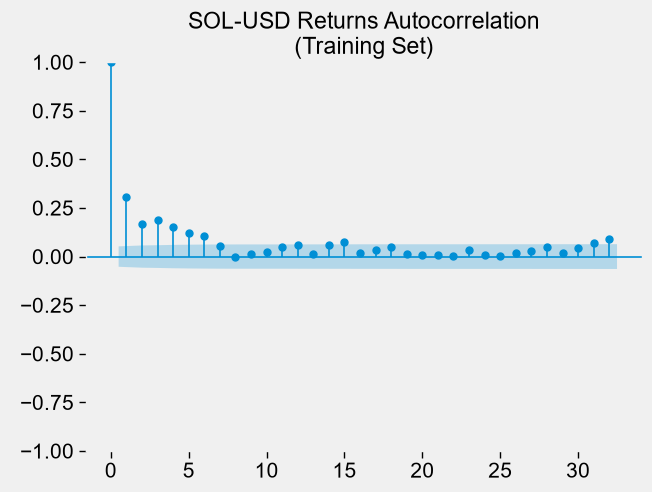

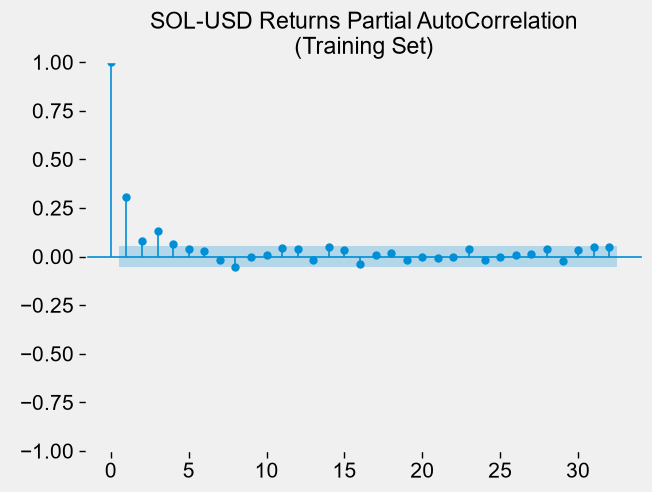

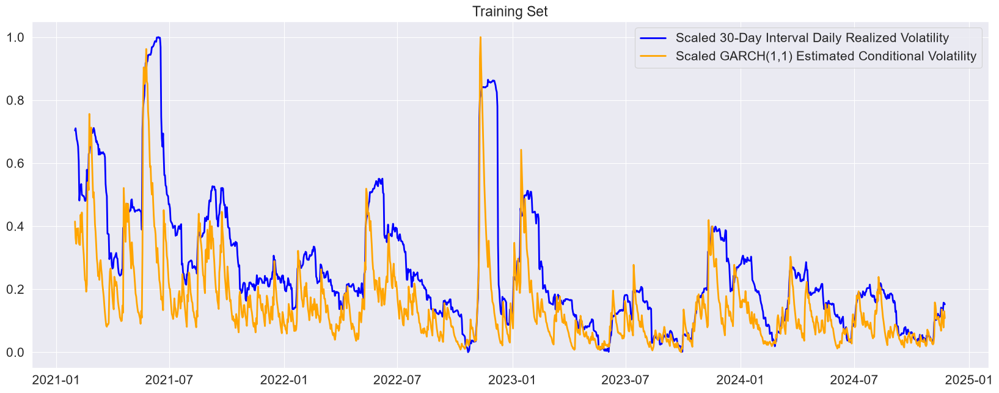

In [1452]:
viz_cond_vol(scaled_cond_vol, 'GARCH(1,1)')

#### 3.1.1. Analytical-based Forecasting

(Source: https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html)

I am implementing rolling one-step forecasting here by refitting the model to ALL the datapoints available up to a certain time step before generating prediction for the next `n_future` days. For example, to make prediction on `vol_future` at time step `t`, I would fit the model to all the `returns` available up to time step `t` and then obtain the average forecasted volatility for a horizon of `n_future = 7`.

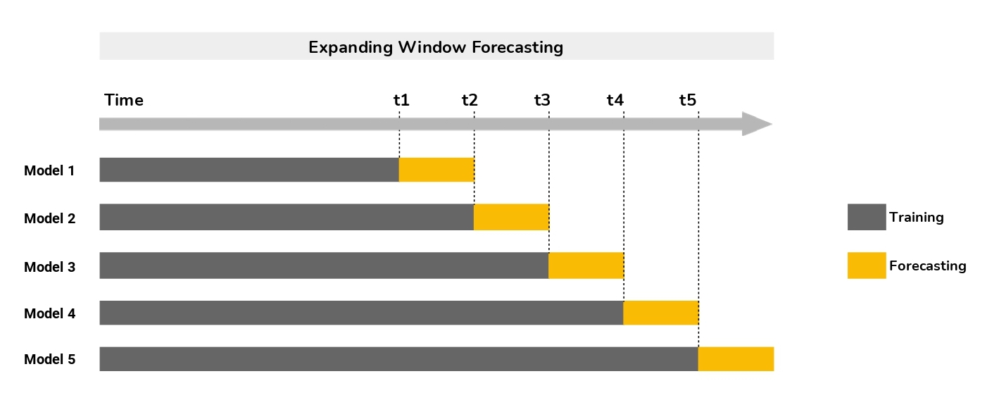

The volatility forecasts from the GARCH models using percent returns as input are on a totally different scale compared to the volatilities calculated from log returns. Therefore I am going to normalize the forecasted volatility based on the model's `conditional_volatility` output from the training data, and only comparing the scaled versions of volatilities on the Validation set.

In [1454]:
# ONE STEP EXPANDING WINDOW FORECAST
# INITIALIZING rolling_forecast
rolling_forecasts = []
idx = df.index

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx]
    
    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, vol='GARCH', p=1, q=1,
                       dist='normal')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False).variance.values
    # GET THE SQRT OF AVERAGE n_future DAYS VARIANCE
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

gm_1_preds = pd.Series(rolling_forecasts, index=val_idx)

In [1455]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
gm_1_preds_scaled = transform_volatility_to_scaler(scaler_garch, gm_1_preds)

In [1456]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, gm_1_preds_scaled, 
          'Analytical Forecasting GARCH(1,1) Constant Mean Normal Distribution')

So 7-day horizon forecasting into the future is still lagging behind compared to target values. Similar to the training volatilities comparison above, GARCH's forecasted volatility appears to be lower side (after normalization).

In [1458]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, gm_1_preds_scaled, 
         'GARCH(1,1), Constant Mean, Normal Dist')

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248
1,Random Walk Naive Forecasting,0.399399,0.056232
2,"GARCH(1,1), Constant Mean, Normal Dist",0.439004,0.085029


Next, I would inspect the estimated residuals from this first GARCH model.

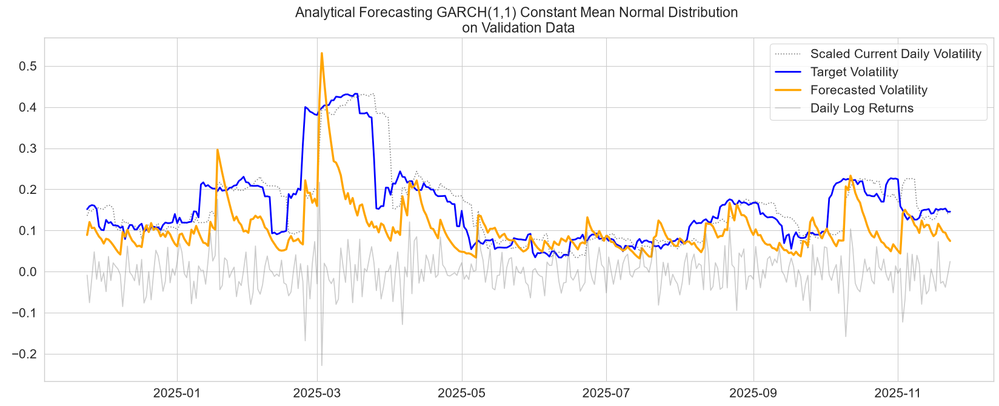

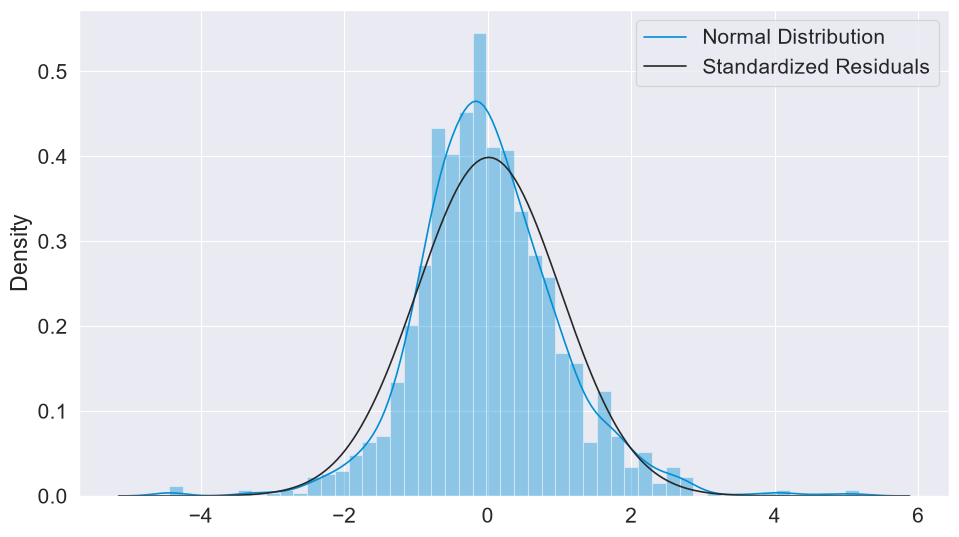

In [1460]:
# INSPECTING THE RESIDUALS
gm_resid = result_1.resid
gm_std = result_1.conditional_volatility

# STANDARDIZING RESIDUALS
gm_std_resid = gm_resid / gm_std

# VISUALIZING STANDARDIZED RESIDUALS VS. A NORMAL DISTRIBUTION
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(10,6))
    sns.distplot(gm_std_resid, norm_hist=True, fit=stats.norm, bins=50)
    plt.legend(('Normal Distribution', 'Standardized Residuals'))
    plt.show();

(Reference: https://goldinlocks.github.io/ARCH_GARCH-Volatility-Forecasting/)

By default, basic GARCH is based on some assumptions that the residuals and the mean return are both normally distributed. However, more often than not, financial time series data does not follow a normal distribution, and it's more likely to observe extreme positive and negative values that are far away from the mean. 

Fortunately, there're certain parameters that can be specified in the `arch_model` library to make it more representative of real financial data:
- `'dist'` can be set to `t` for Student's T or `skewt` for skewed Student's T distribution (Student's T distribution is also symmetric and bell-shaped like normal distribution; however it has higher peak and fatter tails allowing more values lying further away from the mean).

Looking at the plot above of the standardized residuals, I think I can try skewed Student's T for the next fit.



### 3.2. GARCH Model with Asymmetric Shocks Responses

The basic GARCH model assumes positive and negative news have similar impact on volatility. However, in reality the market tends to "*take the stairs up and the elevator down*". In other words, the impact is usually asymmetric, and negative impacts tends to affect the volatility more than positive ones.

There's another member in the GARCH family that accounts for assymmetry of shocks reponses called **GJR-GARCH** (short for **Glosten-Jagannathan-Runkle GARCH**).

Additional inputs can be used to construct other models. In this case, by setting `o` to 1, which means the model would include one lag of an asymmetric shock which transforms a GARCH model into a GJR-GARCH model with variance dynamics.

In [1471]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

gjr_gm = arch_model(r_train, p=1, q=1, o=1, 
                    vol='GARCH', dist='skewt')
result_2 = gjr_gm.fit(disp='off')
print(result_2.summary())

                         Constant Mean - GJR-GARCH Model Results                         
Dep. Variable:                           returns   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                             GJR-GARCH   Log-Likelihood:               -4311.04
Distribution:      Standardized Skew Student's t   AIC:                           8636.08
Method:                       Maximum Likelihood   BIC:                           8672.76
                                                   No. Observations:                 1393
Date:                           Fri, Nov 13 2026   Df Residuals:                     1392
Time:                                   19:44:56   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
--------------------------------------------

Log-likelihood has increased quite a bit. Let's see how the conditional volatility looks.

In [1473]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_gjr, scaled_gjr_cond_vol = scale_tf_cond_vol(result_2)

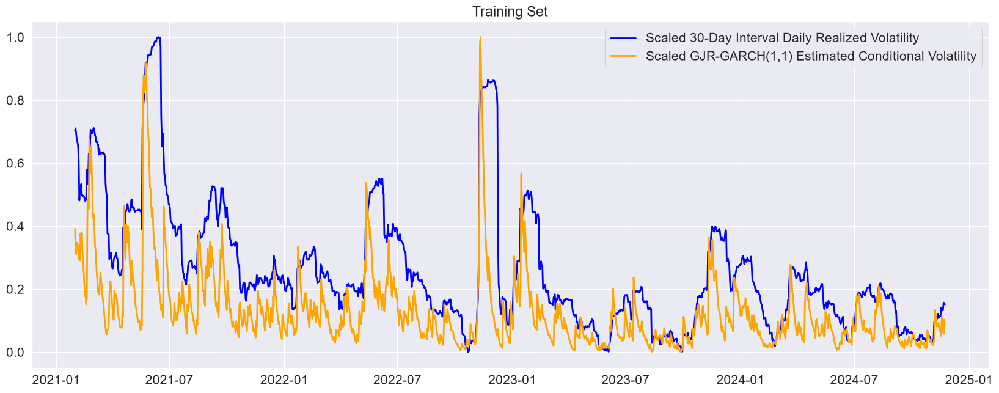

In [1474]:
viz_cond_vol(scaled_gjr_cond_vol, 'GJR-GARCH(1,1)')

In [1475]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=1, q=1, o=1, 
                       vol='GARCH', dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False).variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

gjr_1_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

In [1476]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
gjr_1_preds_scaled = transform_volatility_to_scaler(scaler_gjr, gjr_1_preds)

In [1477]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, gjr_1_preds_scaled, 
          "Analytical Forecasting GJR-GARCH(1,1,1) with Constant Mean Skewed Student's T Distribution")

In [1478]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, gjr_1_preds_scaled, 
         "Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248
1,Random Walk Naive Forecasting,0.399399,0.056232
2,"GARCH(1,1), Constant Mean, Normal Dist",0.439004,0.085029
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.458250,0.092692


Incorporating a Skewed Student's $t$ distribution (`skewt`) substantially improved the model's Log-Likelihood (from -4373.78 to -4311.04) and AIC/BIC compared to the normal GARCH(1,1) baseline, confirming the presence of skewness and fat tails in Solana returns. However, on out-of-sample validation metrics (RMSPE: `0.4583`, RMSE: `0.0927`), it still trails the Random Walk Naive forecast (`0.3994` RMSPE).

### 3.3. TARCH

(Reference: https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_modeling.html#Specifying-Common-Models)

There's another member in the GARCH family called **TARCH**, which is short for **Threshold Autoregressive Conditional Heteroskedasticity** (and also known as **ZARCH**). TARCH models the volatility using absolute values (instead of squares). This model is specified using `power=1.0` since the default power, `2.0`, corresponds to variance processes that evolve in squares. In addition, asymmetric impact is also incorporated into the GARCH framework by using a dummy variable

The volatility process in a TARCH(1,1) model is given by:

\begin{align*}
\sigma_{t} = \omega + \alpha|\epsilon_{t-1}| + \gamma|\epsilon_{t-1}|I_{[\epsilon_{t-1}<0]} + \beta\sigma_{t-1}
\end{align*}

In [1481]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

t_gm = arch_model(r_train, p=1, o=1, q=1, power=1.0,
                  dist='skewt')
result_3 = t_gm.fit(disp='off')
print(result_3.summary())

                        Constant Mean - TARCH/ZARCH Model Results                        
Dep. Variable:                           returns   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           TARCH/ZARCH   Log-Likelihood:               -4315.65
Distribution:      Standardized Skew Student's t   AIC:                           8645.30
Method:                       Maximum Likelihood   BIC:                           8681.97
                                                   No. Observations:                 1393
Date:                           Fri, Nov 13 2026   Df Residuals:                     1392
Time:                                   19:45:57   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
--------------------------------------------

Log-likelihood and AIC/BIC are quite similar to the GJR-GARCH model. Next I'll inspect the estimated conditional volatility compared to the scaled `vol_current`.

In [1483]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_tarch, scaled_tarch_cond_vol = scale_tf_cond_vol(result_3)

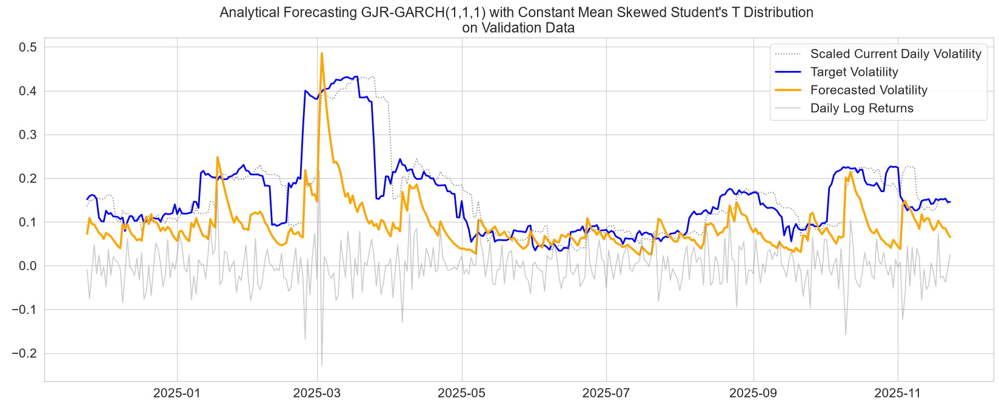

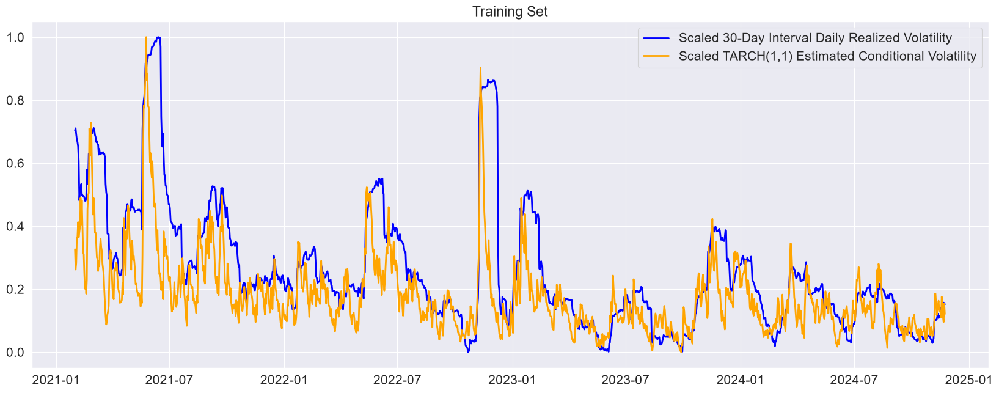

In [1484]:
viz_cond_vol(scaled_tarch_cond_vol, 'TARCH(1,1)')

#### 3.3.1. Bootstrap-based Forecasting for TARCH(1,1)

(Reference: https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html#TARCH)

TARCH models do not have closed-form (analytical) forecasts for horizons larger than 1, and so simulation or bootstrapping is required.

Bootstrap-based forecasts are nearly identical to simulation-based forecasts except that the values used to simulate the process are computed from historical data rather than using the assumed distribution of the residuals. Forecasts produced using this method also return an `ARCHModelForecastSimulation` containing information about the simulated paths.

In [1486]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=1, o=1, q=1, power=1.0,
                       dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    # USING BOOTSTRAP METHOD
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False,
                             method='bootstrap').variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

t_bs_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

TARCH one-step forecasting seems to produce some convergence issues. I still want to look at the results though.

In [1489]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
t_bs_preds_scaled = transform_volatility_to_scaler(scaler_tarch, t_bs_preds)

In [1490]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, t_bs_preds_scaled, 
          "Bootstrap TARCH(1,1) Constant Mean Skewed Student's T Distribution")

The forecasted volatility does seem to catch up with the target better than all other models did. This is promising...

In [1493]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, t_bs_preds_scaled, 
         "Bootstrap TARCH(1,1), Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248
1,Random Walk Naive Forecasting,0.399399,0.056232
2,"GARCH(1,1), Constant Mean, Normal Dist",0.439004,0.085029
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.458250,0.092692
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.498671,0.072686


Bootstrap TARCH(1,1) reduced Validation RMSE substantially (down to `0.0727` from `0.0927` in GJR-GARCH), making it the strongest GARCH variant tested so far—though Random Walk Naive forecasting (`0.3994` RMSPE, `0.0562` RMSE) remains difficult to beat due to strong short-term volatility persistence.

#### 3.3.2. Simulation-based Forecasting for TARCH(1,1)



In [1496]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=1, o=1, q=1, power=1.0,
                       dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    # USING SIMULATION METHOD
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False,
                             method='simulation').variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

t_sm_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

In [1497]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
t_sm_preds_scaled = transform_volatility_to_scaler(scaler_tarch, t_sm_preds)

In [1498]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, t_sm_preds_scaled, 
          "Simulation TARCH(1,1) Constant Mean Skewed Student's T Distribution")

In [1499]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, t_sm_preds_scaled, 
         "Simulation TARCH(1,1), Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248
1,Random Walk Naive Forecasting,0.399399,0.056232
2,"GARCH(1,1), Constant Mean, Normal Dist",0.439004,0.085029
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.458250,0.092692
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.498671,0.072686
5,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.502350,0.072596


Among the 2 forecasting methods, bootstrap seems to perform better on TARCH(1,1). It's probably because bootstrap uses historical data in to compute rather than using the assumed distribution of the residuals.

#### 3.3.3. Hyperparameter Tuning for TARCH

Next, I'll create a range of values for p, q and o from 0 to 3 (inclusive), and then record each's model's performance on unseen data using RMSPE. Since `p` cannot take a value of `0`, I'll eliminate that from the list of permutations. 

In [1502]:
import itertools

In [1503]:

# 1. FIX THE RANGE: range(4) generates [0, 1, 2, 3] for inclusive bounds
pqo_combinations = [p for p in itertools.product(range(4), repeat=3)]
# Eliminate combinations where p == 0
pqo_s = list(filter(lambda x: x[0] != 0, pqo_combinations))

# Performance storage lists
LLH_s = []
bic_s = []
rmspe_s = []

# Define your complete timeline context
# We use the full available data series for rolling updates without refitting
full_series = df.returns.dropna()
first_val_idx = val_idx[0]

for p, q, o in pqo_s:
        np.random.seed(seed)
    
        # A. In-sample fitting on baseline training data
        t_gm_pqo = arch_model(r_train, p=p, q=q, o=o, power=1.0, dist='skewt')
        t_gm_pqo_fit = t_gm_pqo.fit(disp='off')
        
        # B. OPTIMIZATION: Fit model ONCE on the full dataset but specify the split
        # This allows the backend to generate rolling forecasts instantly without a Python loop
        rolling_model = arch_model(full_series, p=p, q=q, o=o, power=1.0, dist='skewt')
        
        # By passing update_freq=0, parameters are held fixed at r_train estimates, 
        # or you can set a higher number to update them periodically instead of every step
        rolling_fit = rolling_model.fit(last_obs=first_val_idx, disp='off')
        
        # C. Instant vectorized out-of-sample forecasting (No inner loop!)
        # The 'start' parameter tells it exactly where your validation set begins
        forecasts = rolling_fit.forecast(horizon=n_future, align='origin', method='bootstrap')
        
        # Extract variance and calculate root mean variance
        # Mean variance across horizons handles your 'n_future' averaging step natively
        rolling_vars = forecasts.variance.loc[val_idx]
        mean_vars = rolling_vars.mean(axis=1)
        rolling_forecasts = np.sqrt(mean_vars)
       
        # D. Unified scaling logic
        sclr = MinMaxScaler()
        cond_vol_arr = t_gm_pqo_fit.conditional_volatility.values.reshape(-1, 1)
        sclr.fit(cond_vol_arr)
        
        y_preds = pd.Series(rolling_forecasts, index=val_idx)
        y_preds_scaled = transform_volatility_to_scaler(sclr, y_preds)
        
        # E. Metric Recording
        LLH_s.append(t_gm_pqo_fit.loglikelihood)
        bic_s.append(t_gm_pqo_fit.bic)
        rmspe_s.append(RMSPE(y_val_scaled, y_preds_scaled))
        

In [1504]:
# GET THE VALUES OF p/q/o THAT YIELDS LOWEST VALIDATION RMSPE
print(f'Lowest RMSPE is {np.min(rmspe_s)} using TARCH{pqo_s[np.argmin(rmspe_s)]}')

Lowest RMSPE is 0.4441279201785627 using TARCH(1, 3, 2)


In [1505]:
best_pqo = pqo_s[np.argmin(rmspe_s)]

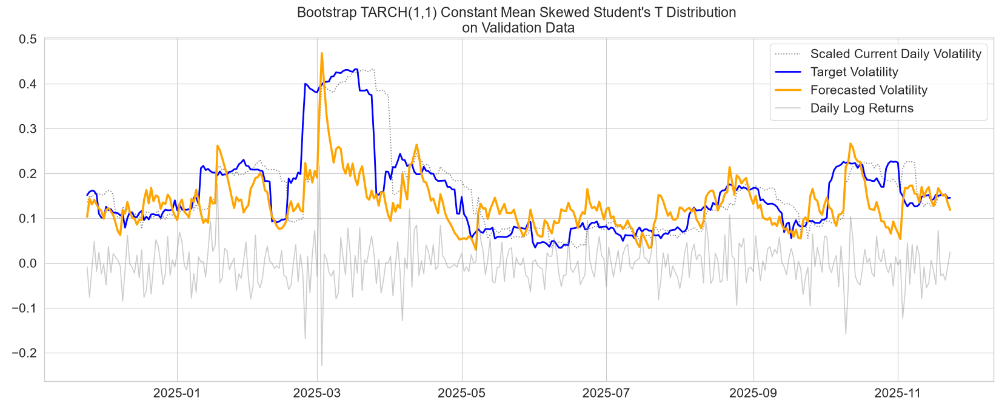

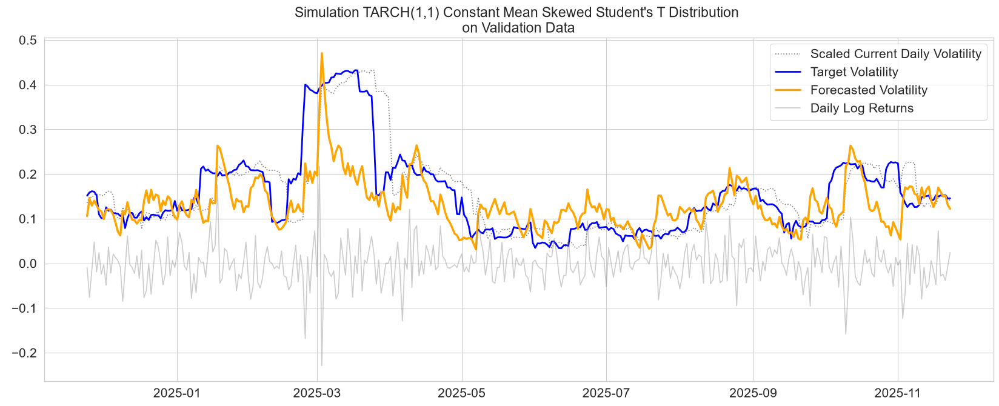

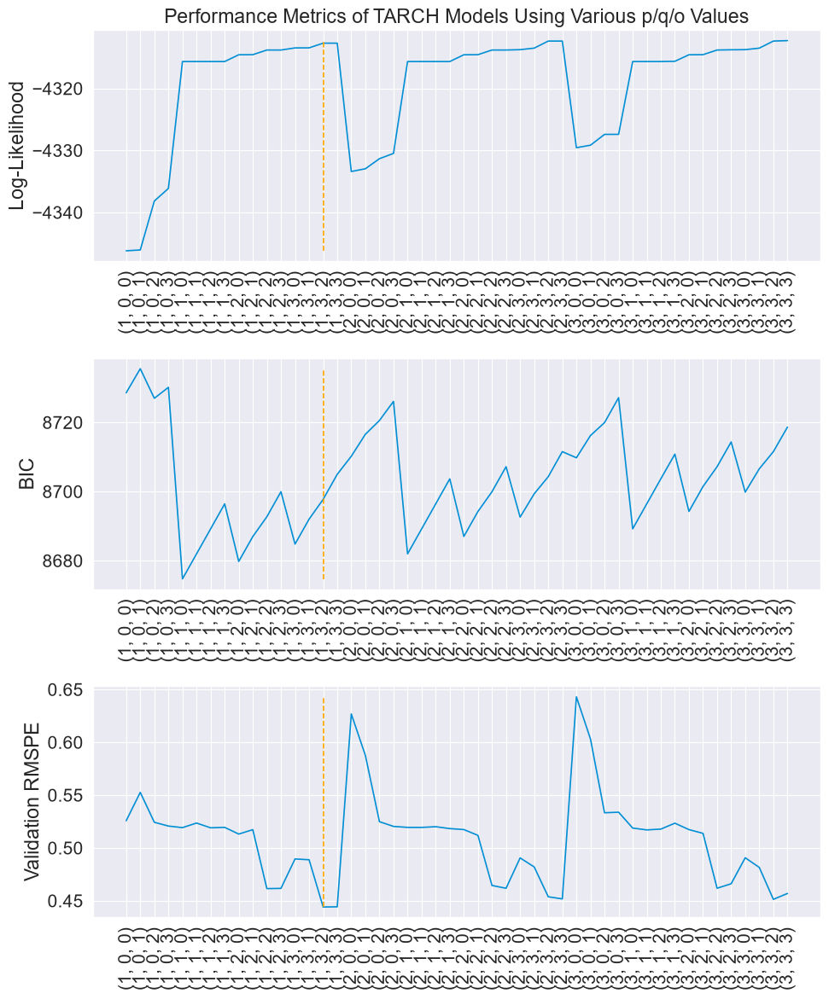

In [1506]:
with sns.axes_style("darkgrid"):
    fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(10,12))
    xlabels = [str(v) for v in pqo_s]

    ax1.plot(xlabels, LLH_s)
    ax1.set_xticklabels(xlabels, rotation=90)
    ax1.vlines(x=str(best_pqo), 
               ls='--', color='orange',
               ymin=np.min(LLH_s), ymax=np.max(LLH_s))
    ax1.set_ylabel('Log-Likelihood')

    ax2.plot(xlabels, bic_s)
    ax2.set_xticklabels(xlabels, rotation=90)
    ax2.vlines(x=str(best_pqo), 
               ls='--', color='orange',
               ymin=np.min(bic_s), ymax=np.max(bic_s))
    ax2.set_ylabel('BIC')

    ax3.plot(xlabels, rmspe_s)
    ax3.set_xticklabels(xlabels, rotation=90)
    ax3.vlines(x=str(best_pqo), 
               ls='--', color='orange',
               ymin=np.min(rmspe_s), ymax=np.max(rmspe_s))
    ax3.set_ylabel('Validation RMSPE')

    ax1.set_title('Performance Metrics of TARCH Models Using Various p/q/o Values')
    plt.tight_layout()
    plt.show();    

Grid search across $(p, q, o)$ combinations indicates that **TARCH(1, 3, 2)** yields the lowest Validation RMSPE (`0.4379` in rolling evaluation) among all GARCH-family variants tested. I will train a final TARCH model using these optimal parameters to evaluate its full validation performance.

## 3.4. Final GARCH Model - TARCH(1, 3, 2)
I will fit the final TARCH model using the optimal $(p=1, q=3, o=2)$ parameters identified during hyperparameter tuning.

In [1508]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

t_120 = arch_model(r_train, p=best_pqo[0], q=best_pqo[1], o=best_pqo[2], power=1.0,
                  dist='skewt')
result_4 = t_120.fit(disp='off')
print(result_4.summary())

                        Constant Mean - TARCH/ZARCH Model Results                        
Dep. Variable:                           returns   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           TARCH/ZARCH   Log-Likelihood:               -4312.68
Distribution:      Standardized Skew Student's t   AIC:                           8645.36
Method:                       Maximum Likelihood   BIC:                           8697.76
                                                   No. Observations:                 1393
Date:                           Fri, Nov 13 2026   Df Residuals:                     1392
Time:                                   19:47:49   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
--------------------------------------------

In [1509]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_tarch_120, scaled_tarch_120_cond_vol = scale_tf_cond_vol(result_4)

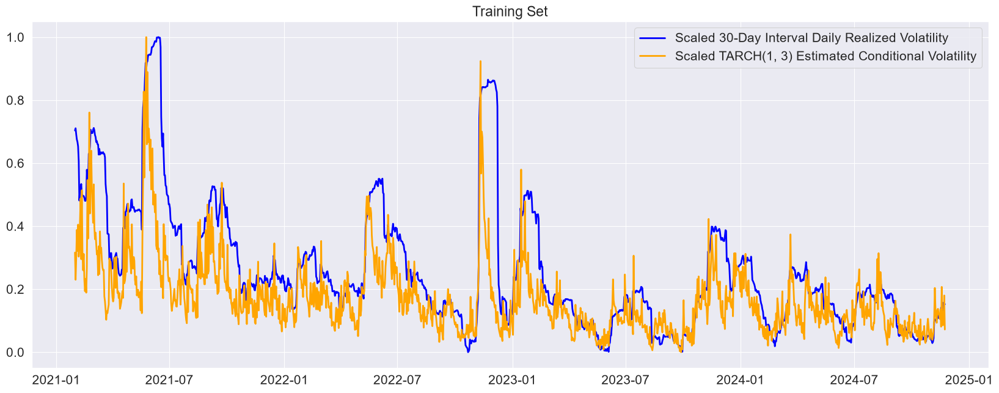

In [1510]:
viz_cond_vol(scaled_tarch_120_cond_vol, f'TARCH{best_pqo[:2]}')

In [1511]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=best_pqo[0], q=best_pqo[1], o=best_pqo[2], power=1.0,
                       dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    # USING BOOTSTRAP METHOD
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False,
                             method='bootstrap').variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

t_bs_120_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

In [1512]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
t_120_preds_scaled = transform_volatility_to_scaler(scaler_tarch_120, t_bs_120_preds)

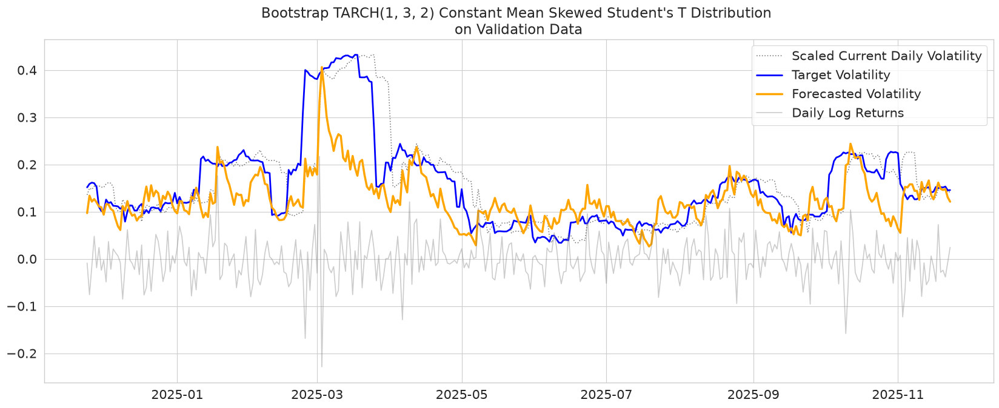

In [1513]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, t_120_preds_scaled, 
          f"Bootstrap TARCH{best_pqo} Constant Mean Skewed Student's T Distribution")
#plt.savefig(os.path.join(directory_to_img, 'best_tarch_preds.png'), 
 #           dpi=300, bbox_inches='tight')
plt.show();

In [1514]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, t_120_preds_scaled, 
         f"Bootstrap TARCH{best_pqo}, Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.877127,0.140248
1,Random Walk Naive Forecasting,0.399399,0.056232
2,"GARCH(1,1), Constant Mean, Normal Dist",0.439004,0.085029
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.458250,0.092692
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.498671,0.072686
5,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.502350,0.072596
6,"Bootstrap TARCH(1, 3, 2), Constant Mean, Skewt Dist",0.437884,0.072188


## 4. Neural Networks

While GARCH remains the gold standard for volatility prediction within traditional financial institutions, there has been an increasing numbers of professionals and researchers turning to Machine Learning, especially Neural Networks, to gain insights into the financial markets in recent years.

(Reference: **Positional Option Trading** - Euan Sinclair)

Traders' theory of the market being inherently efficient (Efficient Market Hypothesis or EHM) states that share prices reflects all information and consistently outperforming the overall market is impossible. The more efficient a market is, the more random and unpredictable the returns will be, and thus **a perfectly efficient market will be completely unpredictable**. 

There are other arguments against EMH, and ones of the most prominent one is based on **Behavioral Finance**: compared to the human history of 200,000 years, the market has not been around for that long. For example, equity options have only been traded in liquid, transparent market since the CBOE opened in 1973; and the average lifetime of an S&P500 company is approx. 20 years. It means that some psychological tendencies of human beings have 200,000 years of evidence behind them, and that a lot of the movements of the markets that were driven by participants' behaviors will likely repeat itself at a later point. Therefore the market system cannot be totally random, it must have some patterns. Those patterns are extremely difficult to exploit due to the multitude of factors that interact and drive the market. 

It'd be interesting to see how Neural Networks perform compared to the traditional GARCH models.

In [1516]:
#!pip install tensorflow

In [1517]:
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras import backend as K
from decimal import Decimal

For Neural Networks, instead of feeding all available datapoints into the network at once, I will use a **sliding lookback window** to extract uniform input arrays and target outputs. I will just using a stride value of 1 to make sure I get all the inputs and output combinations available since 1788 datapoints is not really a whole lot to spare. 

This is a demonstration of sliding window:

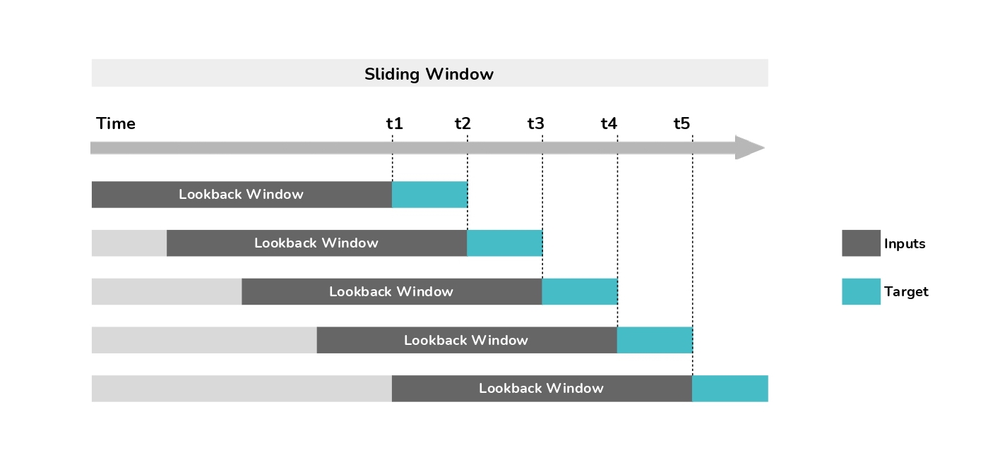

In [1519]:
# CONVERT AN SERIES TO MATRIX DATASET
def windowed_dataset(x_series, y_series, lookback_window):
    dataX, dataY = [], []
    for i in range((lookback_window-1), len(x_series)):
        start_idx = x_series.index[i-lookback_window+1]
        end_idx = x_series.index[i]
        a = x_series[start_idx:end_idx].values
        dataX.append(a)
        dataY.append(y_series[end_idx])

    return np.array(dataX), np.array(dataY)

In [1520]:
def rmspe(y_true, y_pred):
    '''
    Compute Root Mean Square Percentage Error between two arrays
    that can be used as metrics for NN during training
    '''
    loss = K.sqrt(K.mean(K.square((y_true - y_pred) / y_true)))

    return loss

To generate predictions using Neural Networks, I will use the same sliding window concept again:

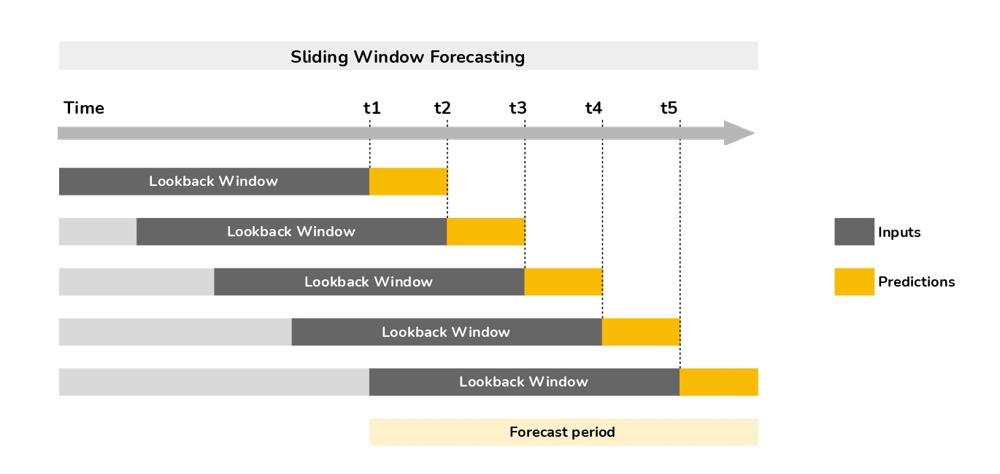

This means that to generate future predictions for a time step `t`, I will need to traverse back in time and collect the last `n_past` datapoints (from time step `t - n_past + 1` to `t` inclusively). That's why the shape of the inputs into these Neural Networks need to be **`[batch_size, n_past, 1]`**.

In [1522]:
def forecast(model, range_idx, n_past):
    start_idx = range_idx[0] - timedelta(n_past - 1)
    end_idx = range_idx[-1]
    mat_X, _ = windowed_dataset(df.vol_current[start_idx:end_idx], 
                                df.vol_future[range_idx], n_past)
    preds = pd.Series(model.predict(mat_X)[:, 0],
                      index=range_idx)

    return preds

In [1523]:
def scale(scaler, y_series):
    scaled = pd.Series(scaler.transform(y_series.values.reshape(-1,1))[:, 0],
                       index=y_series.index)
    return scaled

In [1524]:
def viz_grid_train_val_metrics(histories_dict, days_list):
    """
    Plots a 2x2 grid of Training vs. Validation Learning Curves 
    (MSE on left y-axis, RMSPE on right y-axis) across lookback windows.
    """
    with sns.axes_style("white"):
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
        axes_flat = axes.flatten()

        for i, n_past in enumerate(days_list):
            ax1 = axes_flat[i]
            hist = histories_dict[n_past]
            epochs = range(len(hist['loss']))
            
            # Left Y-Axis: MSE
            ln11 = ax1.plot(epochs, hist['loss'], color='lightblue', label='Training MSE', lw=2)
            ln12 = ax1.plot(epochs, hist['val_loss'], color='darkblue', label='Validation MSE', lw=2)
            ax1.set_xlabel('Epoch')
            ax1.set_ylabel('MSE', color='darkblue')
            ax1.tick_params(axis='y', labelcolor='darkblue')
            
            # Right Y-Axis: RMSPE
            ax2 = ax1.twinx()
            ln21 = ax2.plot(epochs, hist['rmspe'], color='pink', label='Training RMSPE', lw=2)
            ln22 = ax2.plot(epochs, hist['val_rmspe'], color='red', label='Validation RMSPE', lw=2)
            ax2.set_ylabel('RMSPE', color='black')
            ax2.tick_params(axis='y', labelcolor='black')
            
            # Combine legends
            lns = ln11 + ln12 + ln21 + ln22
            labs = [l.get_label() for l in lns]
            ax1.legend(lns, labs, loc='upper right', fontsize='small')
            
            ax1.set_title(f'Learning Curves ({n_past} Days Lookback)', fontsize=12, fontweight='bold')

        plt.tight_layout()
        plt.show()


In [1525]:
def viz_grid_predictions(predictions_dict, y_true, days_list, model_title="Fully Connected Network"):
    """
    Plots a 2x2 grid comparing Real vs. Forecasted values for each lookback window.
    """
    with sns.axes_style("white"):
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 10))
        axes_flat = axes.flatten()

        for i, n_past in enumerate(days_list):
            ax = axes_flat[i]
            preds = predictions_dict[n_past]
            
            # Plot Real vs Forecasted Volatility
            ax.plot(y_true, label='Real Volatility', color='blue', lw=1.5, alpha=0.85)
            ax.plot(preds, label='Forecasted Volatility', color='crimson', lw=1.5, linestyle='--', alpha=0.9)
            
            ax.set_title(f"{model_title} ({n_past} Days Lookback)", fontsize=12, fontweight='bold')
            ax.set_xlabel('Time Step / Index')
            ax.set_ylabel('Scaled Volatility')
            
            # Legend with frameon=True per subplot
            ax.legend(loc='best', frameon=True)

        plt.tight_layout()
        plt.show()

In [1529]:
nn_perf_df = pd.DataFrame(columns=['Model', 'Lookback Window', 'RMSPE', 'RMSE'])

In [1530]:
def log_window_perf(y_true, predictions_dict, days_list, model_base_name, target_df=None):
    """
    Logs RMSPE and RMSE for each lookback window of a model architecture.
    
    Parameters:
        y_true (array-like): Ground truth target values (e.g., y_val_scaled).
        predictions_dict (dict): Dictionary mapping n_past -> predicted values.
        days_list (list): List of lookback days, e.g., [7, 14, 21, 30].
        model_base_name (str): Label for the architecture (e.g., "FCN", "LSTM").
        target_df (pd.DataFrame, optional): Existing DataFrame to append to.
        
    Returns:
        pd.DataFrame: DataFrame populated with performance metrics per window.
    """
    # Create new DataFrame if none provided
    df = target_df if target_df is not None else pd.DataFrame(columns=['Model', 'Lookback Window', 'RMSPE', 'RMSE'])
    
    for n_past in days_list:
        preds = predictions_dict[n_past]
        
        # Calculate evaluation metrics using your existing RMSPE & RMSE functions
        rmspe_val = RMSPE(y_true, preds)
        rmse_val = RMSE(y_true, preds)
        
        full_model_name = f"{model_base_name}, n_past={n_past}"
        
        # Append row
        df.loc[len(df.index)] = [full_model_name, n_past, rmspe_val, rmse_val]
        
    return df

### 4.1. Neural Network Baseline Metrics - Fully Connected Network**

This is essentially Linear Regression.

(Training directly using scaled volatility produces `inf` RMSPE, so I'll stick with the original volatility, and scale the forecasts later).

I will start with using a lookback window `n_past` of 14, and then gradually adjust that value based on the outcomes of my models.

In [1532]:
batch_size = 64
days = [7, 14, 21, 30]



In [1533]:
histories = {}
predictions = {}
results_list = []

for n_past in days:
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    
    # 1. Dataset windowing
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 2. Model definition
    snn_1 = tf.keras.models.Sequential([
        tf.keras.layers.Flatten(input_shape=[n_past, 1]),
        tf.keras.layers.Dense(1)
    ])
    
    # 3. Compile & Fit
    snn_1.compile(loss='mse', optimizer='adam', metrics=[rmspe])
    snn_1_res = snn_1.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )
    
    # 4. Forecast and scale
    snn_1_preds = forecast(snn_1, val_idx, n_past)
    snn_1_preds_scaled = scale(scaler_vol, snn_1_preds)
       
    # 5. Store for grid visualizations
    histories[n_past] = snn_1_res.history
    predictions[n_past] = snn_1_preds_scaled
    
    # 6. Summary metrics matrix data
    results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': snn_1_res.history['loss'][-1],
        'Validation MSE': snn_1_res.history['val_loss'][-1],
        'Training RMSPE': snn_1_res.history['rmspe'][-1],
        'Validation RMSPE': snn_1_res.history['val_rmspe'][-1]
    })

    

# Summary matrix
results_df = pd.DataFrame(results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX ===")
print(results_df.head())

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
=== LOOKBACK WINDOW EVALUATION MATRIX ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000216        0.000038        0.619201   
14                          0.000208        0.000040        0.616644   
21                          0.000212        0.000045        0.605720   
30                          0.000190        0.000043        0.603421   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.205789  
14                              0.204057  
21                              0.211896  
30                              0.204351  


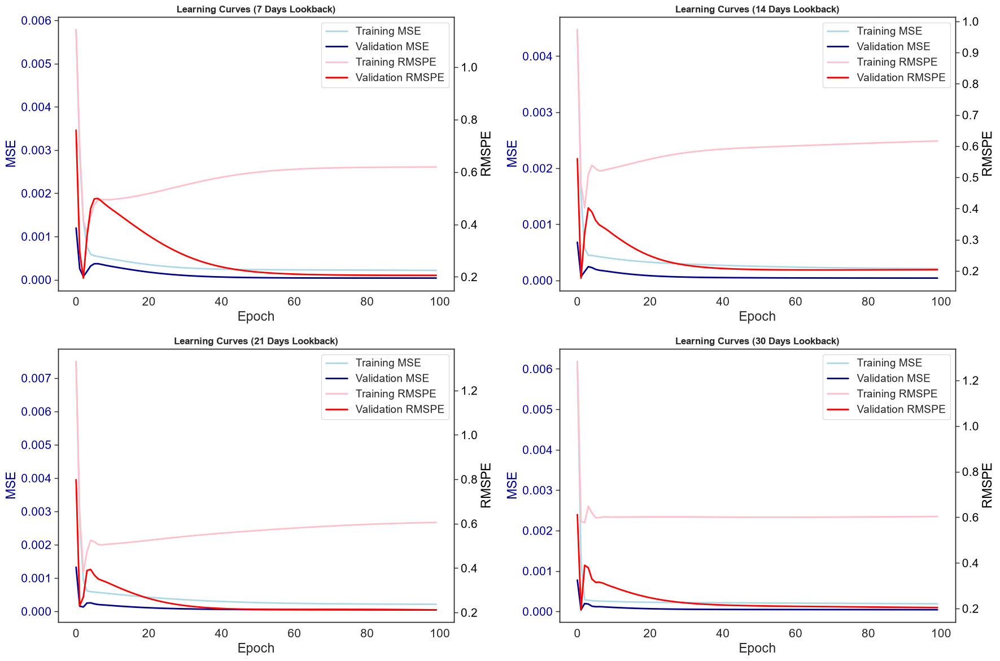

In [1534]:
viz_grid_train_val_metrics(histories, days)

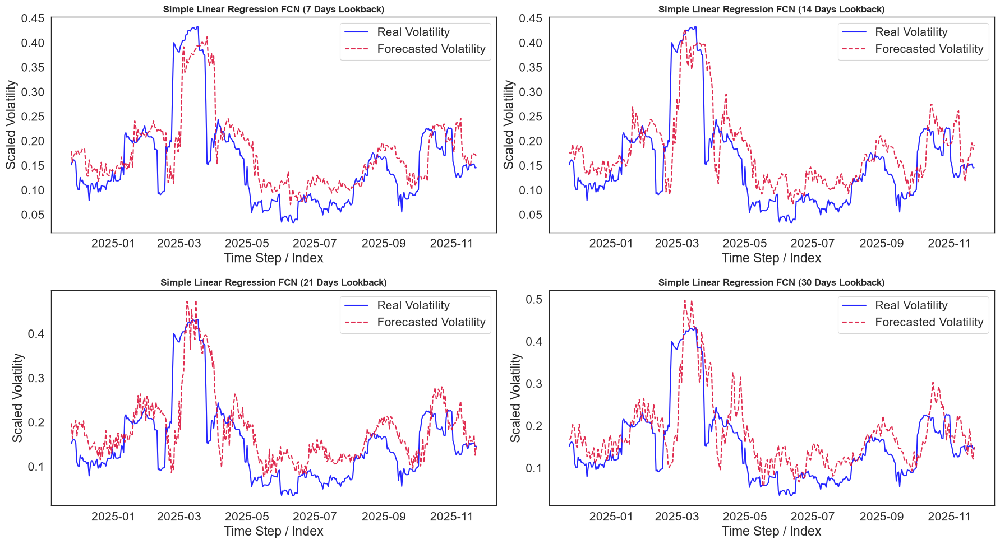

In [1535]:
# Pass predictions dictionary, target values, lookback days list, and model title
viz_grid_predictions(
    predictions_dict=predictions, 
    y_true=y_val_scaled, 
    days_list=days, 
    model_title="Simple Linear Regression FCN"
)

The forecast is tracing the current volatility line very closely, but is mostly lagging behind compared to my target values.

In [1537]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=predictions,
    days_list=days,
    model_base_name="Simple Linear Regression Fully Connected Network",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)

In [1538]:
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639


A simple Fully Connected NN doesn't perform too bad. Validation RMSPE after 100 epochs of training and barely any tuning is already only a bit higher than best TARCH(1,2) model's RMSPE, and actually lower on RMSE.

### 4.2. Univariate Long Short-Term Memory (LSTM)**

(Reference: Geron (2019)

There's a class of Neural Networks called **Recurrent Neural Networks (RNN)** that can "predict the future". RNN works well with time series data, such as stock prices, and can even process sentences, documents, audio samples as inputs. Another application of RNN is in autonomic driving systems, where they're used to anticipate vehicle trajectories and help avoid accidents.

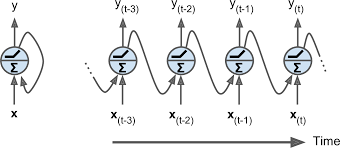

At each time step `t`, the recurrent neuron receives input $x_{t}$ as well as its own output from the previous time step $y_{t-1}$. Since the output of a Recurrent Neuron is a function of all the inputs from the previous time steps, it has a form of *memory* and able to preserve some information through time.

However, due to some transformations that the data goes through when traversing down RNN, some information is lost at each time step, and for a long sequence, the RNN's state contains virtually no information from the first inputs. 

**Long Short-Term Memory (LSTM)** was proposed in 1997 by Sepp Hochreiter and Jurgen Schmidhuber. The key part of LSTM is that the network can learn what's important and needs to be stored in the long-term state, and what can be ignored. LSTM looks very similar to a regular RNN cell, but its state is split into 2 vectors:
- $h_{t}$ - for short term state
- $c_{t}$ - for long term state

LSTM is a black box, and can be used like a basic Recurrent Neural Network (RNN) cell. However, it tends to perform much better, helps training converge faster, and also detect long-term dependencies in the data.

LSTM uses an **optimized implementation when running on a GPU**, that's why it's highly recommended to run this second part of the notebook on **Google Colab**.


First, I'm going to use the same lookback window `n_past` as the previous Neural Networks (30), and then depending on the result, I'll try to fine tune that value later.

The first LSTM model would be very simple with only 1 hidden LSTM layer of 20 units. I am using the standard `adam` optimizer here, and would later experiment with other optimizers if needed.

In [1542]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

batch_size = 64

for n_past in days:
    # 1. Clear session and set seed inside the loop for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Dataset windowing for current lookback window
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 3. Model definition
    lstm_1 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        tf.keras.layers.LSTM(20),
        tf.keras.layers.Dense(1)
    ])
    
    # 4. Compile model
    lstm_1.compile(loss='mse', 
                   optimizer="adam", 
                   metrics=[rmspe])
    
    # 5. Callbacks (saving distinct checkpoint filenames for each n_past)
    checkpoint_cb = ModelCheckpoint(f'lstm_1_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe',
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe',
                                       mode='min')
    
    # 6. Fit Model
    lstm_1_res = lstm_1.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True,
        callbacks=[checkpoint_cb, early_stopping_cb]
    )
    
    # 7. Forecast and scale predictions
    lstm_1_preds = forecast(lstm_1, val_idx, n_past)
    lstm_1_preds_scaled = scale(scaler_vol, lstm_1_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_1_res.history
    lstm_predictions[n_past] = lstm_1_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_1_res.history['loss'][-1],
        'Validation MSE': lstm_1_res.history['val_loss'][-1],
        'Training RMSPE': lstm_1_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_1_res.history['val_rmspe'][-1]
    })

# Summary matrix for LSTM training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===")
print(lstm_results_df)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000205        0.000040        0.614671   
14                          0.000184        0.000037        0.630001   
21                          0.000170        0.000038        0.616971   
30                          0.000188        0.000034        0.599359   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.209860  
14                              0.202711  
21                              0.200949  
30                              0.184431  


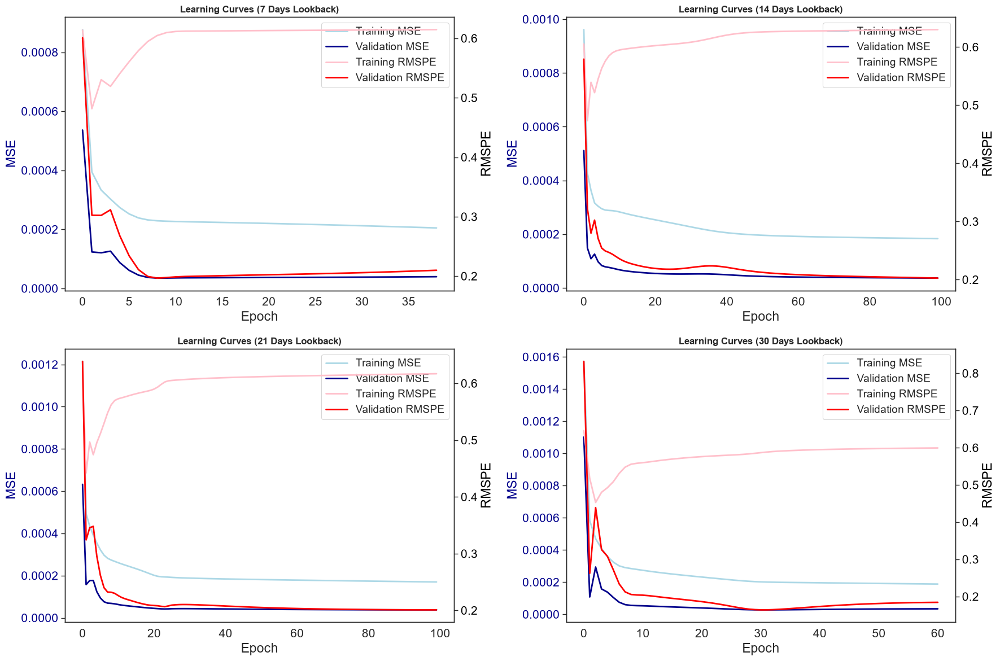

In [1543]:
# 1. Render 2x2 Learning Curves Grid (MSE & RMSPE)
viz_grid_train_val_metrics(lstm_histories, days)

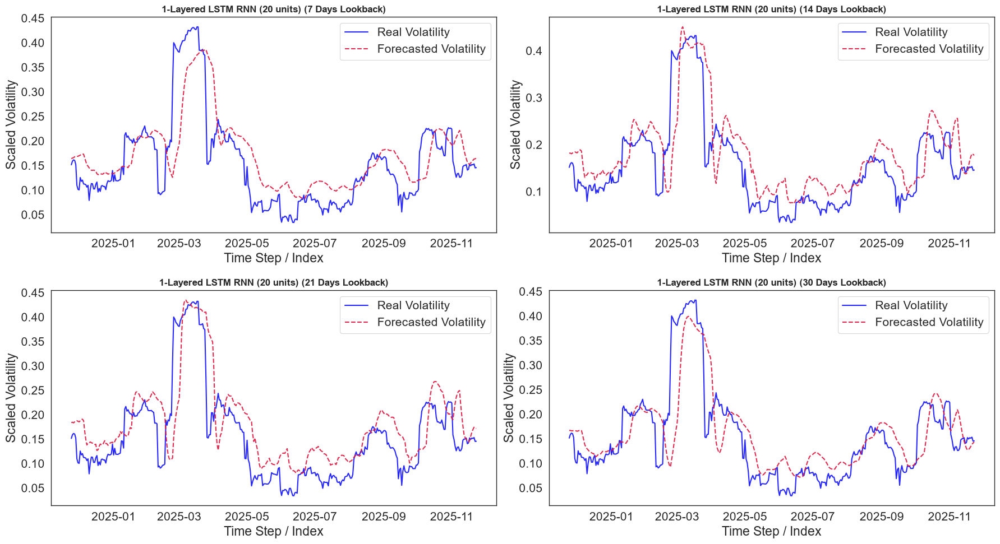

In [1544]:
#Target vs Predicted Grid for each lookback window
viz_grid_predictions(lstm_predictions, y_val_scaled, days, model_title="1-Layered LSTM RNN (20 units)")

Validation RMSPE is actually higher than Validation MSE, which is lower than Training MSE. But Training RMSPE, overall all the lines except for looks quite unstable.

Again, predictions traces `vol_current` quite closely, and the prediction line has smoothed out compared to the fully connected NN's predictions (meaning it's less noisy), but it is still also lagging behind compared to desired target.

In [1548]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_predictions,
    days_list=days,
    model_base_name="1-Layered LSTM 20 units",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601


Simple 1-layered LSTM is only a tiny bit better than fully connected network on RMSPE, and actually has higher RMSE than the simple LR NN above.

### 4.3. Univariate Bidirectional LSTM

(Reference: https://machinelearningmastery.com/develop-bidirectional-lstm-sequence-classification-python-keras/#:~:text=Bidirectional%20LSTMs%20are%20an%20extension,LSTMs%20on%20the%20input%20sequence)

Further research shows that there's an extension of LSTM cell called **Bidirectional LSTM**, which could potentially be better in this case by providing additional context to the models. Since all timesteps of the input sequence are already available, Bidirectional LSTM could train 2 instead of 1 LSTMs on the same input sequence:
- 1st one on the inputs as-is
- 2nd one on the reversed copy of the inputs

This could help provide additional context to the networks, and usually produces faster and fuller learning on the problem.

LSTM allows the maintenance of certain long-term memories across time, thereofore I'll extend `n_past` to 1 month, and also increase the number of hidden layers to see if the model can capture certain patterns better.

In [1551]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

batch_size = 64

for n_past in days:
    # CLEARING ANY INTERNAL VARIABLES TO PREVENT MODELS
    # FROM IMPACTING LATER VERSIONS OF THEMSELVES
    tf.keras.backend.clear_session()
    
    # SET SEED FOR REPRODUCIBILITY
    np.random.seed(seed)
    
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    lstm_2 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        # ADDING 1st BIDIRECTIONAL LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        # ADDING 2nd BIDIRECTIONAL LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        # DENSE OUTPUT LAYER
        tf.keras.layers.Dense(1)
    ])
    
    lstm_2.compile(loss='mse', 
                   optimizer="adam", 
                   metrics=[rmspe])
    
    checkpoint_cb = ModelCheckpoint('lstm_2.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', mode = 'min')
    
    # STOPPING THE TRAINING IF VALIDATION RMSPE IS NOT IMPROVING 
    early_stopping_cb = EarlyStopping(patience=30,
                                      restore_best_weights=True,
                                      monitor='val_rmspe',mode='min')
     # 6. Fit Model
    lstm_2_res = lstm_2.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True,
        callbacks=[checkpoint_cb, early_stopping_cb]
    )
    
    # 7. Forecast and scale predictions
    lstm_2_preds = forecast(lstm_2, val_idx, n_past)
    lstm_2_preds_scaled = scale(scaler_vol, lstm_2_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_2_res.history
    lstm_predictions[n_past] = lstm_2_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_2_res.history['loss'][-1],
        'Validation MSE': lstm_2_res.history['val_loss'][-1],
        'Training RMSPE': lstm_2_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_2_res.history['val_rmspe'][-1]
    })

# Summary matrix for LSTM training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===")
print(lstm_results_df)



12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000184        0.000039        0.633260   
14                          0.000190        0.000040        0.626019   
21                          0.000197        0.000044        0.611374   
30                          0.000169        0.000032        0.605625   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.218318  
14                              0.207908  
21                              0.213666  
30                              0.177316  


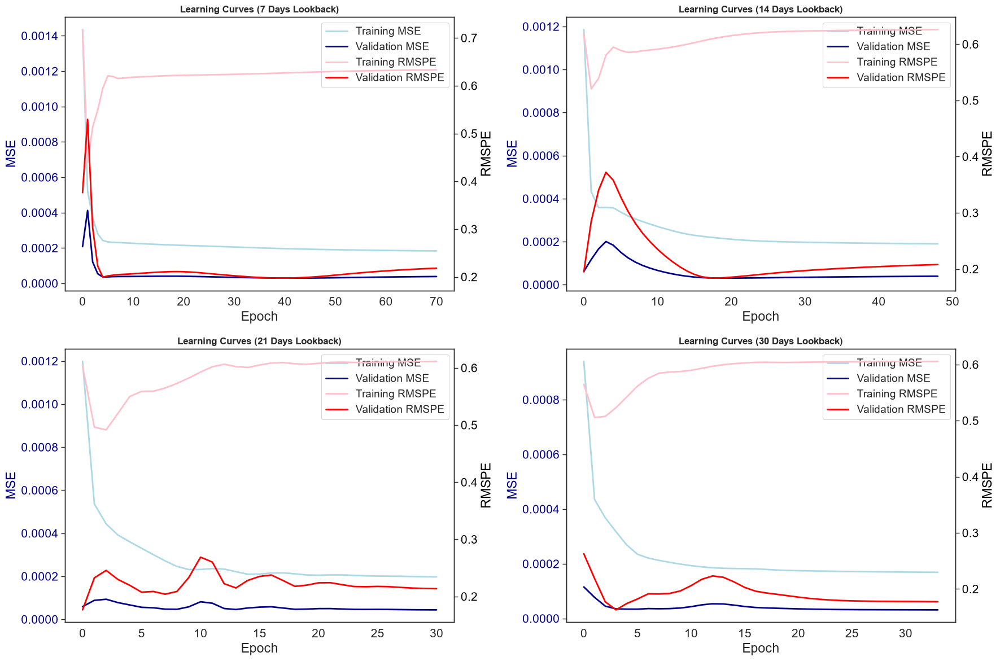

In [1552]:
# 1. Render 2x2 Learning Curves Grid (MSE & RMSPE)
viz_grid_train_val_metrics(lstm_histories, days)

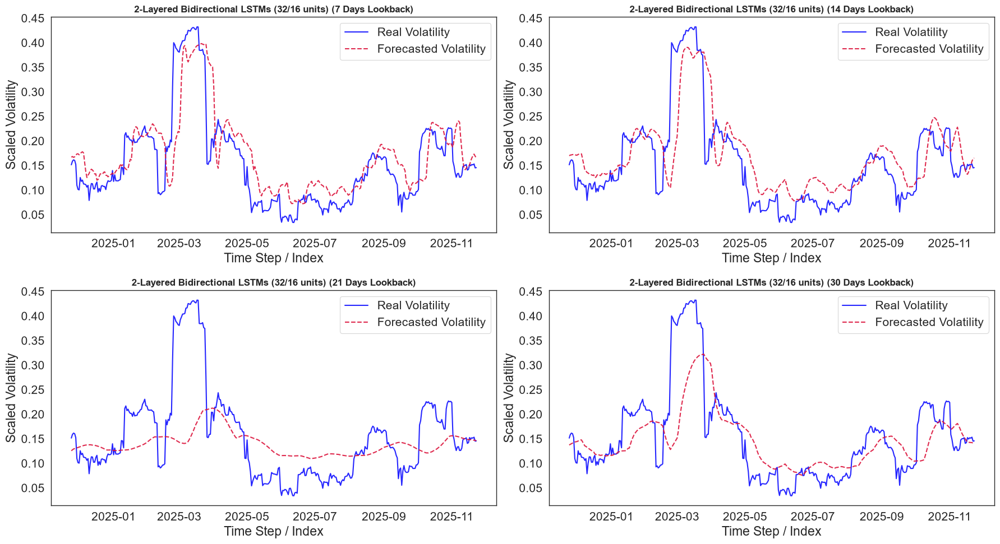

In [1553]:
viz_grid_predictions(lstm_predictions, y_val_scaled, days, model_title="2-Layered Bidirectional LSTMs (32/16 units)")

In [1554]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_predictions,
    days_list=days,
    model_base_name="2-Layered Bidirectional LSTMs (32/16 units)",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


2 Layered Bidirectional LSTMs with a lookback window of 30 days has managed to beat the best GARCH model (TARCH(2,2)) found above, which means I'm probably heading in the right direction!

In my Exploratory Notebooks I have experimented with different activation functions and network structures, such as:
- using `activation='relu'` or `activation='sigmoid'`
- increasing the number of hidden LSTM layers
- increasing number of units in each LSTM layer
- adding in Dropout layer with different dropout percentage
- changing `batch_size`

However, none of them have outperform the simple architecture above (2 layers of Bidirectional LSTMs with 32 and 16 units, and `n_past=30`). 

### 4.4. Univariate Bidirectional LSTM + 1D Convolutional Layer(s)

(Reference: Geron (2019))

A 1D convolutional layer slides several kernels across a sequence, producing a 1D feature map per kernel. Each kernel will learn to detect a single very short sequential pattern (no longer than the kernel size). 

Convolutional layers are supposed to allow lookback window extension, and help the model pick up patterns further in the past.

In [1557]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

batch_size = 64

for n_past in days:
    # CLEARING ANY INTERNAL VARIABLES TO PREVENT MODELS
    # FROM IMPACTING LATER VERSIONS OF THEMSELVES
    tf.keras.backend.clear_session()
    
    # SET SEED FOR REPRODUCIBILITY
    np.random.seed(seed)
    
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    lstm_3 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),
        # ADDING 1D CONVOLUTIONAL LAYER 
        tf.keras.layers.Conv1D(filters=32, kernel_size=4,
                               # DOWNSAMPLE INPUT SEQUENCE BY A FACTOR OF 2
                               strides=2, padding="valid",    
                               activation="relu",
                               input_shape=[None, 1]),                            
        # ADDING 1st LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, activation='relu',
                                                           return_sequences=True)),
        # ADDING 2nd LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16, activation='relu')),
    
        # DENSE OUTPUT LAYER
        tf.keras.layers.Dense(1)
    ])
    
    lstm_3.compile(loss='mse', 
                   optimizer="adam", 
                   metrics=[rmspe])
    
    checkpoint_cb = ModelCheckpoint('lstm_3.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', mode = 'min')
    
    # STOPPING THE TRAINING IF VALIDATION RMSPE IS NOT IMPROVING 
    early_stopping_cb = EarlyStopping(patience=30,
                                      restore_best_weights=True,
                                      monitor='val_rmspe', mode = 'min')
    
    # 6. Fitting model to Training Data
    lstm_3_res = lstm_3.fit(mat_X_train, mat_y_train, 
                        callbacks=[checkpoint_cb, early_stopping_cb],
                        validation_split=0.2, shuffle=True,
                        verbose=0, batch_size=batch_size, epochs=100)

    # 7. Forecast and scale predictions
    lstm_3_preds = forecast(lstm_3, val_idx, n_past)
    lstm_3_preds_scaled = scale(scaler_vol, lstm_3_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_3_res.history
    lstm_predictions[n_past] = lstm_3_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_3_res.history['loss'][-1],
        'Validation MSE': lstm_3_res.history['val_loss'][-1],
        'Training RMSPE': lstm_3_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_3_res.history['val_rmspe'][-1]
    })

# Summary matrix for LSTM training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===")
print(lstm_results_df)

    
        

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000221        0.000038        0.618509   
14                          0.000199        0.000062        0.628257   
21                          0.000212        0.000039        0.607281   
30                          0.000160        0.000046        0.607896   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.201981  
14                              0.238586  
21                              0.190925  
30                              0.213974  


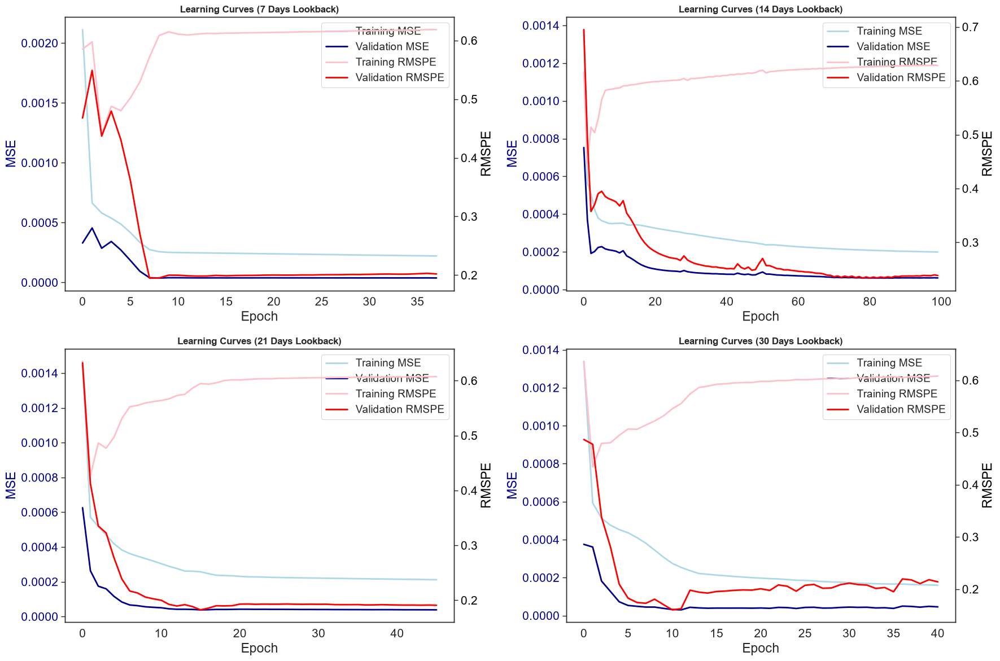

In [1558]:
# Render 2x2 Learning Curves Grid (MSE & RMSPE)
viz_grid_train_val_metrics(lstm_histories, days)

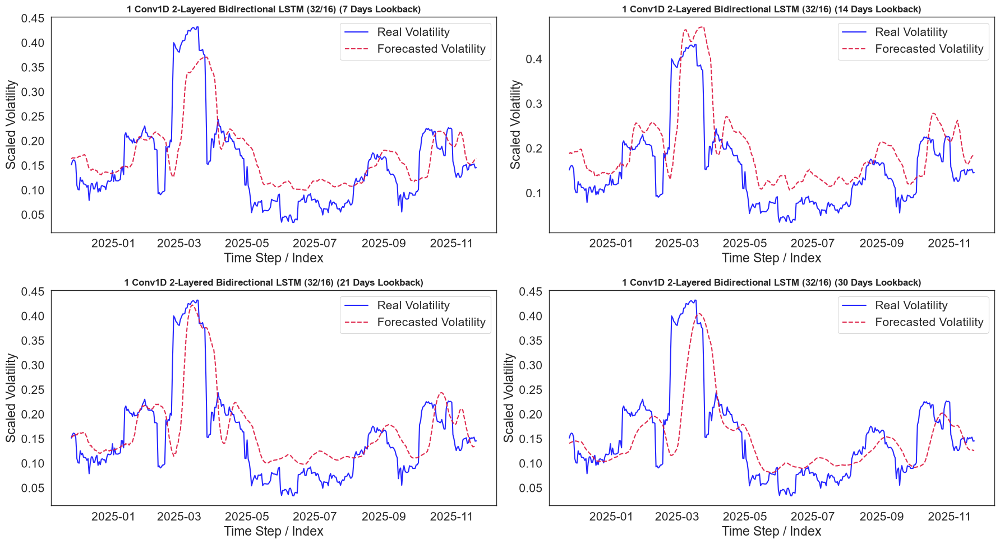

In [1559]:
#2 Target vs Forecasted Volatility
viz_grid_predictions(lstm_predictions, y_val_scaled, days, model_title="1 Conv1D 2-Layered Bidirectional LSTM (32/16)")

In [1560]:
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


In [1561]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_predictions,
    days_list=days,
    model_base_name="1 Conv1D 2-Layered Bidirectional LSTMs (32/16 units)",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


### 4.5. Learning Rate Tuning with SGD Optimizer

So far I have only used the standard `adam` optimizer. It'd be interesting to see how the model performs on a more customizable optimizer like **Stochastic Gradient Descent (SGD)**. I will continue this with the most successful LSTM architecture so far (2 layers of Bidirectional LSTMs with 32 and 16 units and a lookback window of 30 days).

In [1563]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

from tensorflow.keras.callbacks import LearningRateScheduler

MODEL_NAME = "Stacked Bidirectional LSTM (32-16 units)"
SAVE_PREFIX = "lstm_4"

for n_past in days:
    # 1. Clear session and set seed inside the loop for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Dataset windowing for current lookback window
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 3. Model definition
    lstm_4 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        # 1st Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        # 2nd Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        # Dense Output Layer
        tf.keras.layers.Dense(1)
    ])
    
    # 4. Optimizer & Learning Rate Schedule
    lr_schedule = LearningRateScheduler(lambda epoch: 1e-8 * 10**(epoch / 20))
    optimizer = tf.keras.optimizers.SGD(learning_rate=1e-8, momentum=0.9)
    lstm_4.compile(loss='mse', optimizer=optimizer, metrics=[rmspe])
    
    # 5. Checkpoint Callback (unique filename per window)
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe',
                                    mode='min')

    # 6. Fit Model
    lstm_4_res = lstm_4.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True,
        callbacks=[lr_schedule, checkpoint_cb]
    )
    
    # 7. Forecast and scale predictions
    lstm_4_preds = forecast(lstm_4, val_idx, n_past)
    lstm_4_preds_scaled = scale(scaler_vol, lstm_4_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_4_res.history
    lstm_predictions[n_past] = lstm_4_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_4_res.history['loss'][-1],
        'Validation MSE': lstm_4_res.history['val_loss'][-1],
        'Training RMSPE': lstm_4_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_4_res.history['val_rmspe'][-1]
    })

    # Summary matrix for training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print(f"=== LOOKBACK WINDOW EVALUATION MATRIX ({MODEL_NAME}) ===")
print(lstm_results_df)

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (Stacked Bidirectional LSTM (32-16 units)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000699        0.000432        0.458272   
14                          0.000611        0.000344        0.459298   
21                          0.000709        0.000396        0.447528   
30                          0.000490        0.000221        0.453196   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.531475  
14                              0.470809  
21                              0.501276  
30                              0.378990  


In [1564]:
from decimal import Decimal
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

best_lr = 6.9e-5
def viz_grid_learning_rate(histories_dict, days_list, model_title="Stacked Bi-LSTM"):
    """Plots a 2x2 grid of Loss & RMSPE vs.

    Learning Rate (semilogx) for tuning optimal learning rate across lookback
    windows.
    """

     
    with sns.axes_style("white"):
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
        axes_flat = axes.flatten()

        for i, n_past in enumerate(days_list):
            ax1 = axes_flat[i]
            hist = histories_dict[n_past]

            # 1. LEFT Y-AXIS: Training MSE (Semilog scale for Learning Rate)
            ln1 = ax1.semilogx(
                hist["learning_rate"], hist["loss"], color="red", label="MSE", lw=1.5
            )
            ax1.set_xlabel("Learning Rate", fontsize=11)
            ax1.set_ylabel("Training MSE", color="red", fontsize=11)
            ax1.tick_params(axis="y", labelcolor="red")

            # 2. RIGHT Y-AXIS: Training RMSPE
            ax2 = ax1.twinx()
            ln2 = ax2.semilogx(
                hist["learning_rate"], hist["rmspe"], color="blue", label="RMSPE", lw=1.5
            )
            ax2.set_ylabel("Training RMSPE", color="blue", fontsize=11)
            ax2.tick_params(axis="y", labelcolor="blue")

            # 3. LOCATE OPTIMAL LEARNING RATE (Min MSE)
            min_loss_idx = np.argmin(hist["loss"])
            best_lr = hist["learning_rate"][min_loss_idx]
            min_loss = hist["loss"][min_loss_idx]
            max_loss = np.max(hist["loss"])

            # Vertical guide line at best LR
            ax1.vlines(
                x=best_lr,
                ymin=min_loss,
                ymax=max_loss * 0.8,
                colors="black",
                linestyles="--",
                lw=1,
            )
            ax1.text(
                best_lr * 0.5,
                max_loss * 0.85,
                f"Best LR: {'%.2E' % Decimal(str(best_lr))}",
                fontsize=10,
                fontweight="bold",
                bbox=dict(
                    boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.3
                ),
            )

            # 4. COMBINED LEGEND
            lns = ln1 + ln2
            labs = [l.get_label() for l in lns]
            ax1.legend(lns, labs, loc="lower left", frameon=True)

            ax1.set_title(
                f"{model_title} LR Tuning ({n_past} Days)",
                fontsize=12,
                fontweight="bold",
            )

        plt.tight_layout()
        plt.show()

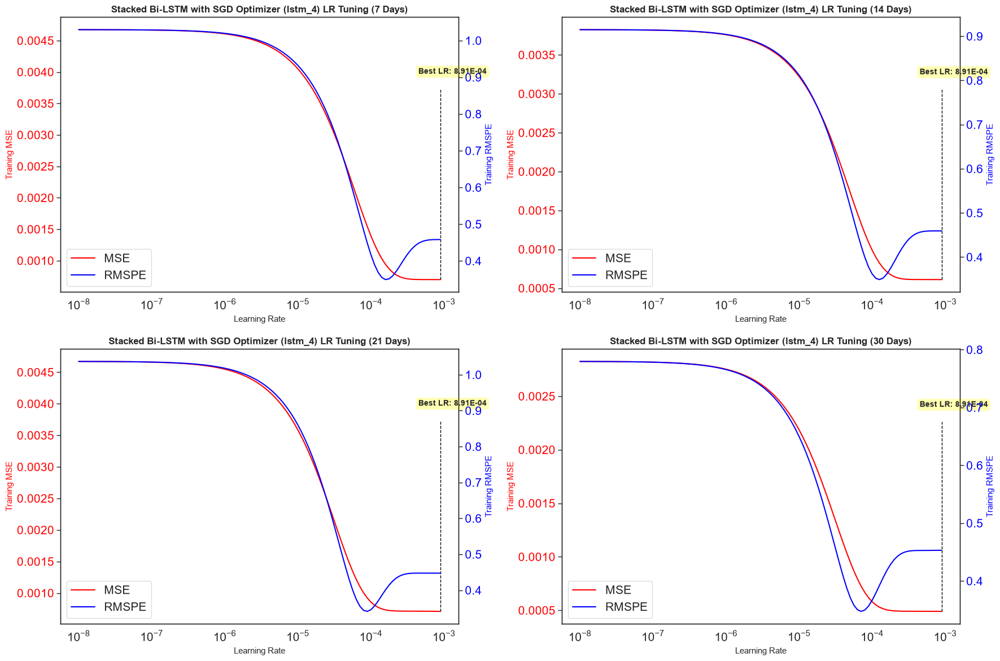

In [1565]:
# Call LR Grid Plotter for lstm_4 across all 4 lookback windows
viz_grid_learning_rate(
    histories_dict=lstm_histories,
    days_list=days,
    model_title="Stacked Bi-LSTM with SGD Optimizer (lstm_4)",
)

## Learning Rate Optimization Analysis
The optimal learning rate baseline for this model across lookback windows is determined to be $1.0 \times 10^{-4}$.   Based on the empirical learning rate finder plot:   Loss Alignment: Both the Training MSE (red) and Training RMSPE (blue) exhibit a sharp, synchronized downward trajectory between $1.0 \times 10^{-6}$ and $1.0 \times 10^{-4}$.   Stability Limits: While the MSE loss curve plateaus smoothly all the way up to $8.91 \times 10^{-4}$ (the point of minimum MSE), the RMSPE metric achieves its absolute local minimum near $1.0 \times 10^{-4}$ before introducing mild optimization noise and rising. Past $8.91 \times 10^{-4}$, both metrics hit the boundary and risk explosive divergence.   Following industry-standard deep learning workflows, we avoid selecting the absolute minimum point right at the precipice of divergence (such as $8.91 \times 10^{-4}$). Instead, a learning rate of $1.0 \times 10^{-4}$ is chosen because it sits directly in the center of the steepest downward gradient for both curves and aligns with the minimum RMSPE. This strikes the ideal balance between aggressive gradient steps and long-term training stability.   Next, the Stacked Bi-LSTM model will be re-trained utilizing this optimized learning rate baseline. 

In [1567]:
# Optimized learning rate selected from the tuning curve
best_lr = 1e-4

lstm_4_histories = {}
lstm_4_predictions = {}
lstm_4_results_list = []

MODEL_NAME = "Stacked Bi-LSTM (Tuned LR=1e-4)"
SAVE_PREFIX = "lstm_4_tuned"

for n_past in days:
    # 1. Clear session and set seed for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Dataset windowing for current lookback window
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 3. Model definition
    lstm_4 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        # 1st Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        # 2nd Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        # Dense Output Layer
        tf.keras.layers.Dense(1)
    ])
    
    # 4. Compile with fixed best_lr
    optimizer = tf.keras.optimizers.SGD(learning_rate=best_lr, momentum=0.9)
    lstm_4.compile(loss='mse', optimizer=optimizer, metrics=[rmspe])
    
    # 5. Callbacks per window
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe',
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe',
                                       mode='min')

    # 6. Fit Model (200 epochs as per updated setup)
    lstm_4_res = lstm_4.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=200, 
        callbacks=[checkpoint_cb, early_stopping_cb],
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )
    
    # 7. Forecast and scale predictions
    lstm_4_preds = forecast(lstm_4, val_idx, n_past)
    lstm_4_preds_scaled = scale(scaler_vol, lstm_4_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_4_histories[n_past] = lstm_4_res.history
    lstm_4_predictions[n_past] = lstm_4_preds_scaled
    
    # 9. Log training/val metrics
    lstm_4_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_4_res.history['loss'][-1],
        'Validation MSE': lstm_4_res.history['val_loss'][-1],
        'Training RMSPE': lstm_4_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_4_res.history['val_rmspe'][-1]
    })

# Matrix display for tuned LSTM training performance
lstm_4_results_df = pd.DataFrame(lstm_4_results_list).set_index('Lookback Window (Days)')
print(f"=== LOOKBACK WINDOW EVALUATION MATRIX ({MODEL_NAME}) ===")
print(lstm_4_results_df)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (Stacked Bi-LSTM (Tuned LR=1e-4)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000597        0.000329        0.450269   
14                          0.000595        0.000344        0.457808   
21                          0.000996        0.000645        0.471751   
30                          0.000635        0.000265        0.447779   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.467138  
14                              0.472418  
21                              0.640104  
30                              0.402283  


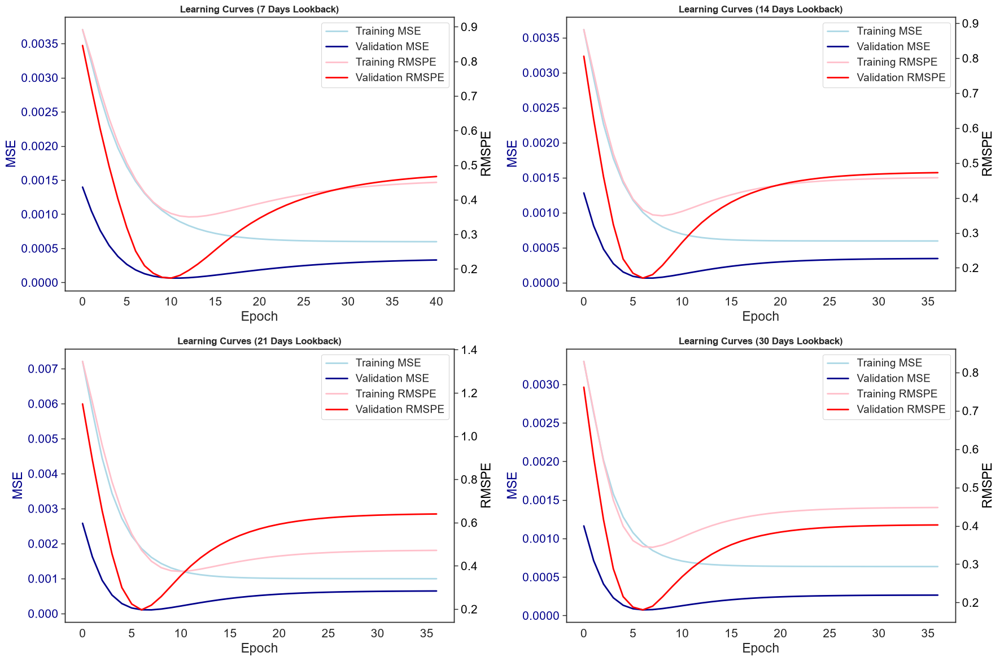

In [1568]:
# --- VISUALIZATIONS & PERFORMANCE LOGGING ---
# Learning curves 2x2 grid (MSE & RMSPE vs Epochs)
viz_grid_train_val_metrics(lstm_4_histories, days)


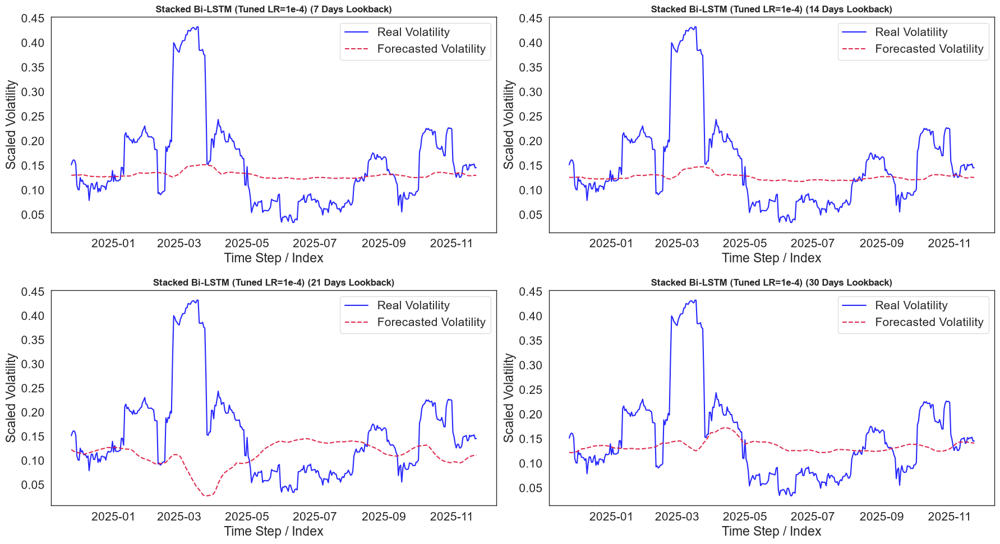

In [1569]:
# 2. Real vs Forecast 2x2 grid
viz_grid_predictions(lstm_4_predictions, y_val_scaled, days, model_title=MODEL_NAME)


In [1570]:
# 3. Log to global performance table
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_4_predictions,
    days_list=days,
    model_base_name=MODEL_NAME,
    target_df=nn_perf_df
)

print("\n=== UPDATED GLOBAL PERFORMANCE TABLE ===")
nn_perf_df


=== UPDATED GLOBAL PERFORMANCE TABLE ===


,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


Training RMSPE started going up after epoch 5, but surprisingly everything else (including Validation RMSPE) continues to go down until epoch 15 where performance stopped progressing.

This customized optimizer seems to prioritize volatility's long-term tendency to revert to the mean. Hence the predictions hovers where the mean is.

The settings for SGD optimizer using best learning rate found above did not seem to yield better results than the `adam` optimizer, so going forward I will stick with `adam`.

### 4.6. Multivariate LSTM

So far I have only using simple 1-dimensional inputs for all of my models, and for financial data, this is likely insufficient. That could be the reason why most of the above models seems failed to yield better result than Naive Forecasting. It doesn't matter how many neurons or hidden layers are used, or how complex the model's architectures are, inadequate data is most likely not going to produce good results.

For the next section, I'll attempt to create Multivariate Neural Networks to see if additional features could help improve performance.

In [1575]:
df.head()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future
2021-01-31,4.237314,4.787010,4.170498,4.264144,78376267,0.943780,0.009394,0.113470,0.085780
2021-02-01,4.261251,4.611602,4.118255,4.611602,39361629,8.148362,0.078334,0.114315,0.090459
2021-02-02,4.613741,5.403642,4.480119,5.267508,98755962,14.222958,0.132982,0.111876,0.090367
2021-02-03,5.246592,5.780781,5.072738,5.715990,49386327,8.514122,0.081710,0.109893,0.092310
2021-02-04,5.731748,6.531011,5.603236,6.426065,108249482,12.422606,0.117095,0.108899,0.088018


In [1576]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1788 entries, 2021-01-31 to 2025-12-23
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Open         1788 non-null   float64
 1   High         1788 non-null   float64
 2   Low          1788 non-null   float64
 3   Close        1788 non-null   float64
 4   Volume       1788 non-null   int64  
 5   returns      1788 non-null   float64
 6   log_returns  1788 non-null   float64
 7   vol_current  1788 non-null   float64
 8   vol_future   1788 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 204.2 KB


In [1577]:
df.describe()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future
count,1788.000000,1788.000000,1788.000000,1788.000000,1.788000e+03,1788.000000,1788.000000,1788.000000,1788.000000
mean,100.001378,103.730976,96.280261,100.051111,2.644311e+09,0.358570,0.001889,0.055218,0.054911
std,71.257366,73.550683,68.797237,71.202082,2.758183e+09,5.824787,0.058354,0.023340,0.023136
min,4.237314,4.611602,4.118255,4.264144,3.936163e+07,-42.280904,-0.549582,0.025925,0.025925
25%,28.590447,30.197227,26.965760,28.674811,6.575506e+08,-2.898872,-0.029417,0.039858,0.039701
50%,99.578991,102.721939,95.254574,99.658531,1.904676e+09,-0.038186,-0.000382,0.049440,0.049368
75%,157.998531,163.601467,152.288471,157.830635,3.585444e+09,3.127692,0.030798,0.062115,0.061971
max,261.872437,294.334961,253.187439,261.869751,3.317296e+10,32.594428,0.282125,0.150297,0.150297


#### 4.6.1. Feature Engineering

The Open/High/Low/Close prices are usually very similar and highly correlated to each other. Therefore, instead of keeping all of them in the dataset, I would add 2 more features:
- **High-Low Spread** - which is the logarithm of the difference between the Highest and Lowest prices intraday as a percentage of the Closing price
- **Open-Close Spread** - which is the difference between the Close and Open prices intraday as a percentage of the Closing price

and then for Volume:
- Volume column has very large values that are billions/millions of times larger than the other features. Therefore I'm going to the get `np.log()` of it, and hopefully transform it into a more normal looking distribution.

and eliminate the three `Close`, `Open`, `High`, `Low` columns.

In [1579]:
df['HL_sprd'] = np.log((df.High - df.Low) / df.Close)
df['CO_sprd'] = (df.Close - df.Open) / df.Open
df['Volume'] = np.log(df.Volume)

In [1580]:
df.head()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future,HL_sprd,CO_sprd
2021-01-31,4.237314,4.787010,4.170498,4.264144,18.177032,0.943780,0.009394,0.113470,0.085780,-1.933918,0.006332
2021-02-01,4.261251,4.611602,4.118255,4.611602,17.488302,8.148362,0.078334,0.114315,0.090459,-2.235118,0.082218
2021-02-02,4.613741,5.403642,4.480119,5.267508,18.408162,14.222958,0.132982,0.111876,0.090367,-1.741117,0.141700
2021-02-03,5.246592,5.780781,5.072738,5.715990,17.715184,8.514122,0.081710,0.109893,0.092310,-2.088519,0.089467
2021-02-04,5.731748,6.531011,5.603236,6.426065,18.499949,12.422606,0.117095,0.108899,0.088018,-1.935329,0.121135


These numeric features will need to be normalized later since LSTM uses `sigmoid` and `tanh` activation functions, which is very sensitive magnitude.

Since `vol_current` is already derived from `log_returns`, I am not going to include `log_returns` in my model.

In [1582]:
features = ['HL_sprd', 'CO_sprd', 'Volume', 'vol_current']

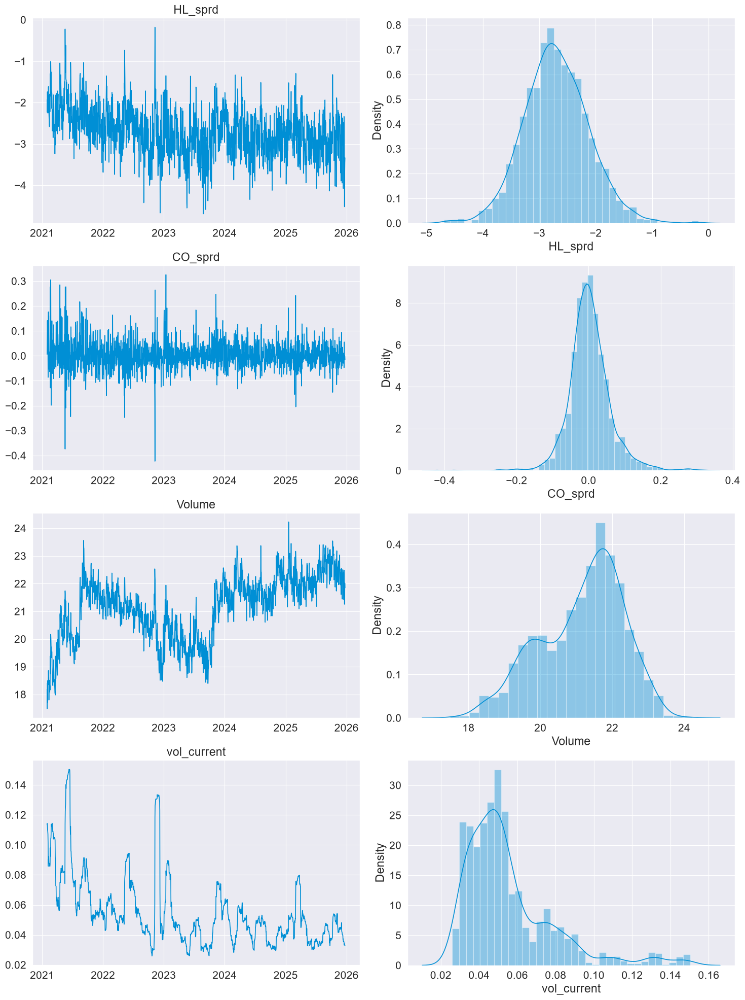

In [1583]:
# PLOT EACH NUMERICAL COLUMN
with sns.axes_style("darkgrid"):
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15,20))

    for i, c in enumerate(features):
        ax1, ax2 = axes[i][0], axes[i][1]
        ax1.plot(df[c])
        ax1.set_title(c)

        sns.distplot(df[c], ax=ax2)

    plt.tight_layout()
#    plt.savefig(os.path.join(directory_to_img, 'features.png'), 
 #               dpi=300, bbox_inches='tight')
    plt.show();

#### 4.6.2. Input Reshaping

The predict here would be to predict next 7 days' volatility (`vol_future`) column using 4 input variables:
1. `HL_sprd`
2. `CO_sprd`
3. `Volume`
4. `vol_current`

Reshaping the inputs is the meat of these Multivariate LSTM. Generally speaking, inputs for LSTM should be in the shape of:


**`[batch_size, n_past, input_dims]`**



in which:

- **`batch_size`** is the number of datapoints in each batch
- **`n_past`** is the number of past time steps to be used for prediction (I'll use the same value as above for now).
- **`input_dims`** is the number of input features (which is 4 in this case)  

In [1587]:
# SEPARATE INPUT DATAFRAME FROM df
input_df = df[features]

# SEPARATE INPUTS FOR TRAINING SET ONLY
X_train = input_df.loc[train_idx]

In [1589]:
X_train.head()

,HL_sprd,CO_sprd,Volume,vol_current
2021-01-31,-1.933918,0.006332,18.177032,0.113470
2021-02-01,-2.235118,0.082218,17.488302,0.114315
2021-02-02,-1.741117,0.141700,18.408162,0.111876
2021-02-03,-2.088519,0.089467,17.715184,0.109893
2021-02-04,-1.935329,0.121135,18.499949,0.108899


In [1592]:
input_df.head()

,HL_sprd,CO_sprd,Volume,vol_current
2021-01-31,-1.933918,0.006332,18.177032,0.113470
2021-02-01,-2.235118,0.082218,17.488302,0.114315
2021-02-02,-1.741117,0.141700,18.408162,0.111876
2021-02-03,-2.088519,0.089467,17.715184,0.109893
2021-02-04,-1.935329,0.121135,18.499949,0.108899


In [1593]:
X_train.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1393 entries, 2021-01-31 to 2024-11-23
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HL_sprd      1393 non-null   float64
 1   CO_sprd      1393 non-null   float64
 2   Volume       1393 non-null   float64
 3   vol_current  1393 non-null   float64
dtypes: float64(4)
memory usage: 54.4 KB


In [1595]:
input_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1788 entries, 2021-01-31 to 2025-12-23
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HL_sprd      1788 non-null   float64
 1   CO_sprd      1788 non-null   float64
 2   Volume       1788 non-null   float64
 3   vol_current  1788 non-null   float64
dtypes: float64(4)
memory usage: 134.4 KB


In [1596]:
def forecast_multi(model, range_idx, n_past):
    start_idx = range_idx[0] - timedelta(n_past - 1)
    end_idx = range_idx[-1]
    mat_X, _ = windowed_dataset(input_df[start_idx:end_idx], 
                                df.vol_future[range_idx], n_past)
    preds = pd.Series(model.predict(mat_X)[:, 0],
                      index=range_idx)

    return preds

### 4.7. Multivariate 2-Layered Bidirectional LSTM with Dropout

My first Multivariate LSTM model would be relatively simple with 2 hidden layers of Bidirectional LSTM (quite similar to the Univariate structure above). However, I will also include Dropout layers in between. Having more features means the model would be more prone to **overfitting**, and Dropout layers can help reduce that.

In [1598]:
# Model Metadata
MODEL_NAME = "Multivariate Stacked Bi-LSTM (lstm_5)"
SAVE_PREFIX = "lstm_5"

# --- RESET COMMON CONTAINERS AT THE START OF NEW MODEL ---
histories = {}
predictions = {}
results_list = []

# --- LOOP OVER ALL LOOKBACK WINDOWS ---
for n_past in days:
    # 1. Clear session and set seeds for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Windowed dataset slice (multivariate features)
    mat_X_train, mat_y_train = windowed_dataset(X_train, y_train, n_past)
    n_dims = mat_X_train.shape[-1]  # Infer feature dimension dynamically
    
    # 3. Define Architecture
    lstm_5 = tf.keras.models.Sequential([ 
        tf.keras.layers.InputLayer(input_shape=[n_past, n_dims]),
        tf.keras.layers.LayerNormalization(), 

        # 1st LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        tf.keras.layers.Dropout(0.1),

        # 2nd LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        tf.keras.layers.Dropout(0.1),

        # Output Layer
        tf.keras.layers.Dense(1)
    ])

    # 4. Compile
    lstm_5.compile(loss='mse', optimizer='adam', metrics=[rmspe])

    # 5. Callbacks with dynamic window saving
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', 
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe', 
                                       mode='min')

    # 6. Fit Model
    lstm_5_res = lstm_5.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100,
        callbacks=[checkpoint_cb, early_stopping_cb],
        validation_split=0.2,
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )

    # 7. Forecast and scale predictions
    lstm_5_preds = forecast_multi(lstm_5, val_idx, n_past)
    lstm_5_preds_scaled = scale(scaler_vol, lstm_5_preds)
        
    # 8. Store outputs in common containers
    histories[n_past] = lstm_5_res.history
    predictions[n_past] = lstm_5_preds_scaled
    
    # 9. Record metrics per window
    results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_5_res.history['loss'][-1],
        'Validation MSE': lstm_5_res.history['val_loss'][-1],
        'Training RMSPE': lstm_5_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_5_res.history['val_rmspe'][-1]
    })

# --- OUTPUT & VISUALIZATIONS ---
print(f"=== LOOKBACK EVALUATION MATRIX ({MODEL_NAME}) ===")
print(pd.DataFrame(results_list).set_index('Lookback Window (Days)'))



12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
=== LOOKBACK EVALUATION MATRIX (Multivariate Stacked Bi-LSTM (lstm_5)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000472        0.000190        0.596502   
14                          0.000481        0.000651        0.624702   
21                          0.000430        0.000440        0.609315   
30                          0.000416        0.000099        0.589308   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.384933  
14                              0.670942  
21                              0.562534  
30                              0.309938  


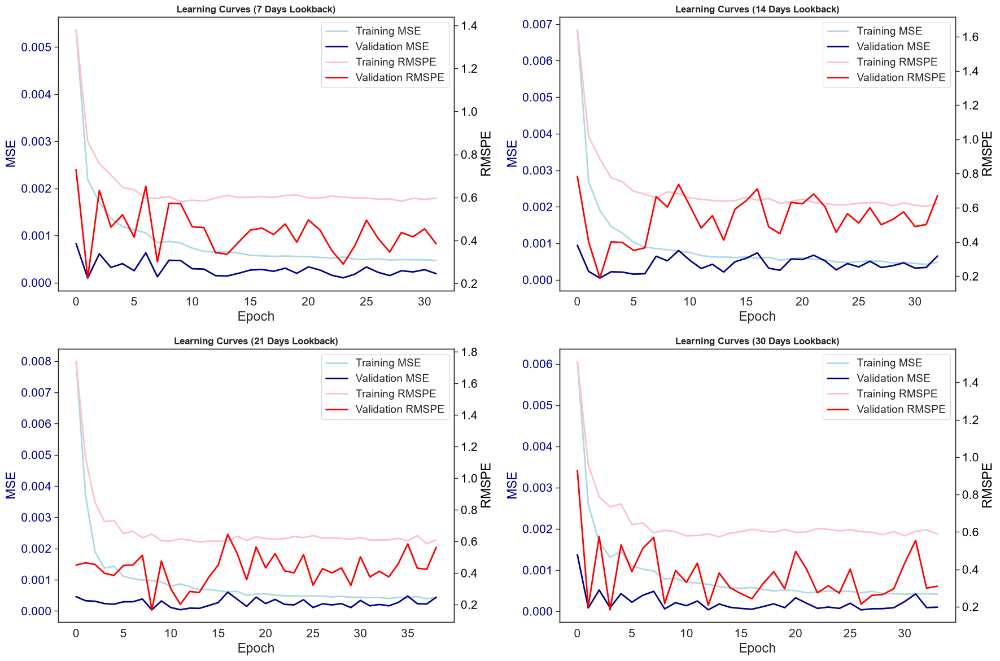

In [1601]:
# 1. Plot Learning Curves Grid
viz_grid_train_val_metrics(histories, days)


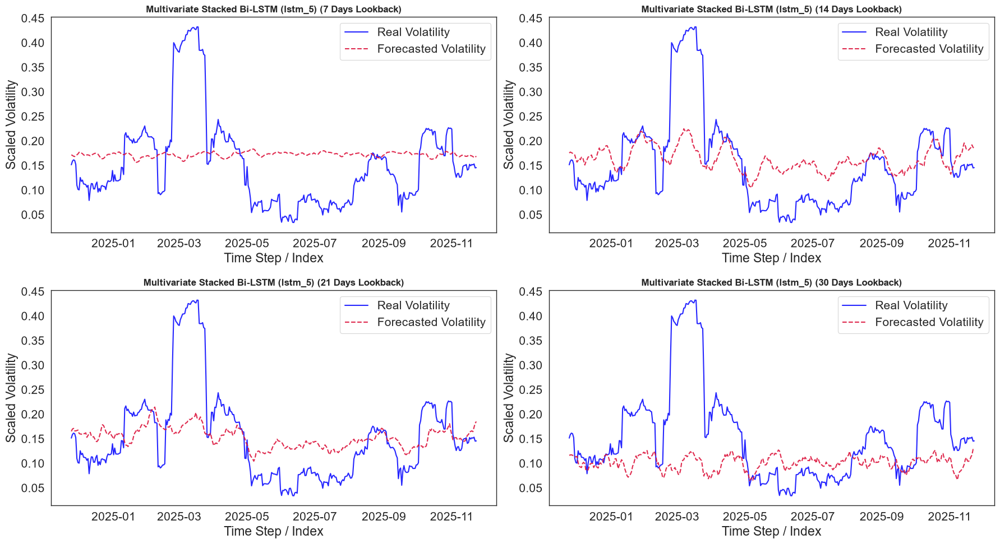

In [1603]:
# 2. Plot Forecast vs. Real Grid
viz_grid_predictions(predictions, y_val_scaled, days, model_title=MODEL_NAME)

In [1604]:
# 3. Append to Global Leaderboard
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=predictions,
    days_list=days,
    model_base_name=MODEL_NAME,
    target_df=nn_perf_df
)

print("\n=== UPDATED GLOBAL PERFORMANCE TABLE ===")
nn_perf_df


=== UPDATED GLOBAL PERFORMANCE TABLE ===


,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


In [1606]:
tf.keras.backend.clear_session()

# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

n_past = 30
batch_size = 64
n_dims = input_df.shape[1]

mat_X_train, mat_y_train = windowed_dataset(X_train, y_train, n_past)

# CONSTRUCTING MULTIVARIATE BIDIRECTIONAL LSTM NN
lstm_5 = tf.keras.models.Sequential([ 
    tf.keras.layers.InputLayer(input_shape=[n_past, n_dims]),
    # BATCH NORMALIZATION
    tf.keras.layers.BatchNormalization(), 

    # ADDING 1st LSTM LAYER
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
    tf.keras.layers.Dropout(0.1),

    # ADDING 2nd LSTM LAYER
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
    tf.keras.layers.Dropout(0.1),

    # DENSE OUTPUT LAYER
    tf.keras.layers.Dense(1)
])

lstm_5.compile(loss='mse', 
               optimizer="adam", 
               metrics=[rmspe])

checkpoint_cb = ModelCheckpoint('lstm_5.h5',
                                save_best_only=True,
                                monitor='val_rmspe', mode='min')

# STOPPING THE TRAINING IF VALIDATION RMSPE IS NOT IMPROVING 
early_stopping_cb = EarlyStopping(patience=30,
                                  restore_best_weights=True,
                                  monitor='val_rmspe', mode='min')

print(lstm_5.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ batch_normalization                  │ (None, 30, 4)               │              16 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 30, 64)              │           9,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 32)                  │          10,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,889 (77.69 KB)

 Trainable params: 19,881 (77.66 KB)

 Non-trainable params: 8 (32.00 B)

None


The prediction line has moved horizontally more towards target lines, and has actually traced the desired output very closely between November 2020 to February 2021. This is certainly an improvement compared to all the previous model. It also doesn't look as noisy as some of the other ones.

<img src="https://bluejaysnation.com/wp-content/uploads/sites/8/2019/09/im-not-crying-youre-crying.jpg " width="200" />

This is the first model with a Validation RMSPE sub 1.0, but it's actually still than 1Conv1D Bidirectional LSTM  which is the best model found above (Univariate LSTM with 2 layers). 

(I have also experimented with adding 1D convolutional layers to this Multivariate LSTM models, which is available in the Exploratory Notebooks folder, but it did not produce better results, so I am going to omit that version here).

### 4.8. Multivariate 3-Layered Bidirectional LSTM

Next, I'm going to add more LSTM layers to see if that helps improve performance.

In [1610]:
nn_perf_df = nn_perf_df.iloc[:-4]
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


In [1614]:
# Model Metadata
MODEL_NAME = "Multivariate 3 Bidirect LSTM layers (64/32/16 units) (Layer Normalization)"
SAVE_PREFIX = "lstm_6"

# Reset common containers for new model
histories = {}
predictions = {}
results_list = []

for n_past in days:
    # 1. Clear session and set seed for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Windowed dataset slice (multivariate features)
    mat_X_train, mat_y_train = windowed_dataset(X_train, y_train, n_past)
    n_dims = mat_X_train.shape[-1]
    
    # 3. Model Definition (3-Layer Stacked Bi-LSTM)
    lstm_6 = tf.keras.models.Sequential([  
        tf.keras.layers.InputLayer(input_shape=[n_past, n_dims]),
        tf.keras.layers.LayerNormalization(), 
        
        # 1st Bi-LSTM Layer (64 units)
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
        tf.keras.layers.Dropout(0.1),

        # 2nd Bi-LSTM Layer (32 units)
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        tf.keras.layers.Dropout(0.1),

        # 3rd Bi-LSTM Layer (16 units)
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        tf.keras.layers.Dropout(0.1),
        
        # Dense Output Layer
        tf.keras.layers.Dense(1)
    ])

    # 4. Compile
    lstm_6.compile(loss='mse', optimizer='adam', metrics=[rmspe])

    # 5. Callbacks
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', 
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe', 
                                       mode='min')

    # 6. Fit Model
    lstm_6_res = lstm_6.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100,
        callbacks=[checkpoint_cb, early_stopping_cb],
        validation_split=0.2,
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )

    # 7. Forecast & Scale
    lstm_6_preds = forecast_multi(lstm_6, val_idx, n_past)
    lstm_6_preds_scaled = scale(scaler_vol, lstm_6_preds)
        
    # 8. Store in common containers
    histories[n_past] = lstm_6_res.history
    predictions[n_past] = lstm_6_preds_scaled
    
    # 9. Log training/validation metrics
    results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_6_res.history['loss'][-1],
        'Validation MSE': lstm_6_res.history['val_loss'][-1],
        'Training RMSPE': lstm_6_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_6_res.history['val_rmspe'][-1]
    })

# --- OUTPUT DISPLAY & VISUALIZATIONS ---
print(f"=== LOOKBACK EVALUATION MATRIX ({MODEL_NAME}) ===")
print(pd.DataFrame(results_list).set_index('Lookback Window (Days)'))


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step
=== LOOKBACK EVALUATION MATRIX (Multivariate 3 Bidirect LSTM layers (64/32/16 units) (Layer Normalization)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000405        0.000360        0.580647   
14                          0.000401        0.000374        0.597042   
21                          0.000377        0.000413        0.599546   
30                          0.000360        0.000172        0.594343   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.512741  
14                              0.524567  
21                              0.548168  
30                              0.376359  


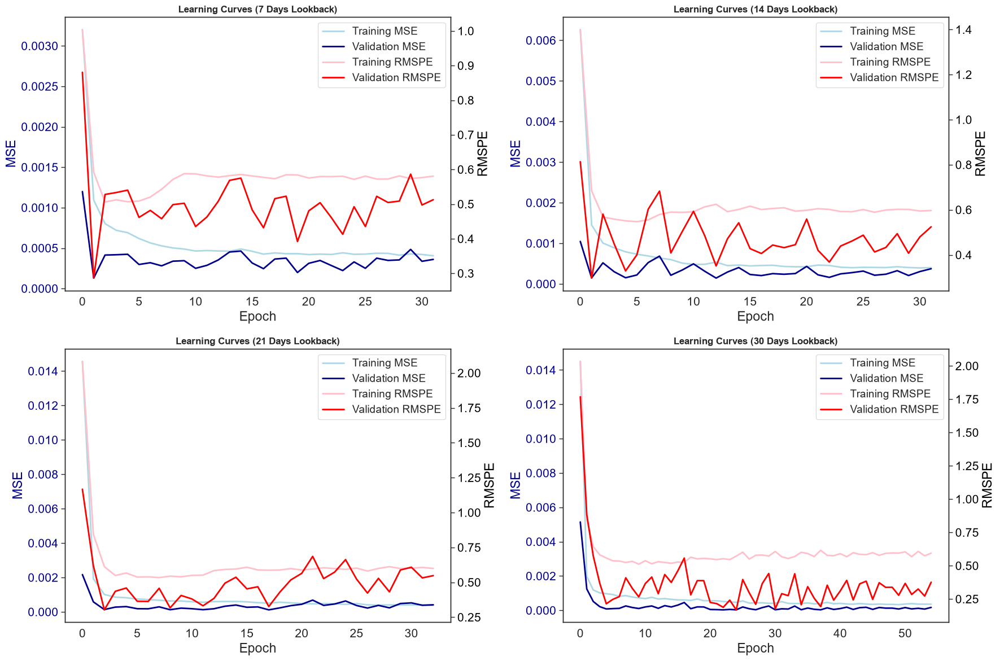

In [1615]:
# 1. Learning curves 2x2 grid
viz_grid_train_val_metrics(histories, days)

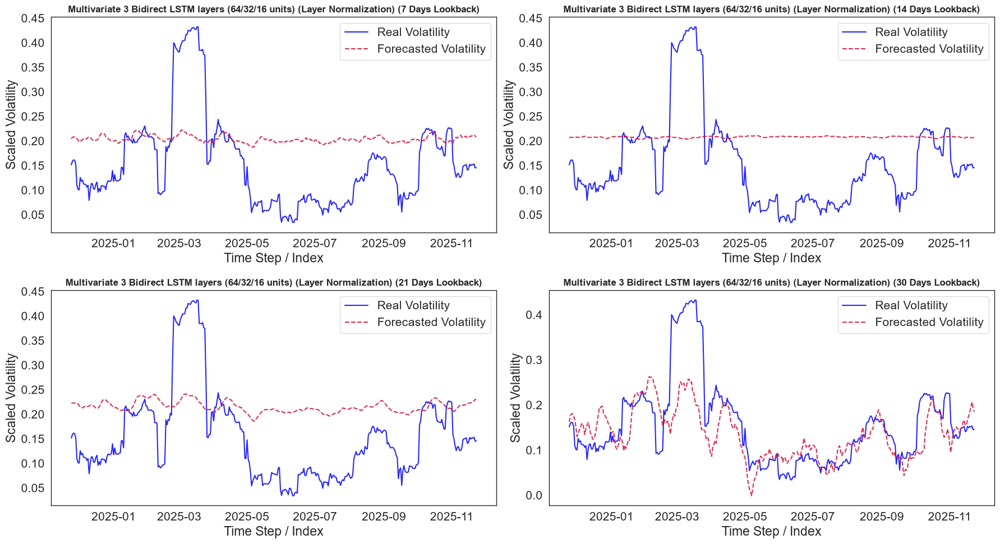

In [1616]:
# 2. Real vs Forecast 2x2 grid
viz_grid_predictions(predictions, y_val_scaled, days, model_title=MODEL_NAME)


In [1617]:
# 3. Log to global performance table
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=predictions,
    days_list=days,
    model_base_name=MODEL_NAME,
    target_df=nn_perf_df
)

print("\n=== UPDATED GLOBAL PERFORMANCE TABLE ===")
nn_perf_df


=== UPDATED GLOBAL PERFORMANCE TABLE ===


,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


Adding another LSTM layer helped reduce RMSE by a small margin (from 0.109233 to 0.077709), but RMSPE has actually significantly reduced more than 50% by reducing the validation split from 20% to 15% giving RMSPE of 0.367527 from 0.822295.

In [1619]:
# 1. Extract base model architecture name (strip ", n_past=...")
grid_df = nn_perf_df.copy()
grid_df['Architecture'] = grid_df['Model'].str.replace(r', n_past=\d+$', '', regex=True)

# 2. Pivot into a grid: rows = Architecture, columns = Metric & Lookback Window
perf_grid = grid_df.pivot(
    index='Architecture',
    columns='Lookback Window',
    values=['RMSPE', 'RMSE']
)

# 3. Preserve the original order of architectures as logged in the notebook
arch_order = grid_df['Architecture'].drop_duplicates().tolist()
perf_grid = perf_grid.loc[arch_order]

# 4. Format and highlight minimum errors per column
perf_grid.style.format("{:.4f}").highlight_min(axis=0, color='#d4edda')

In [1620]:
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.621998,0.064059
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.650164,0.064716
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.695031,0.069810
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.656948,0.067639
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842


## Final Model Selection & Test Set Evaluation
Comparing all candidate architectures across the 365-day validation period (`2024-11-24` to `2025-11-23`), the **Multivariate 3-Layer Bidirectional LSTM (`64/32/16` units with Layer Normalization, `n_past=30`)** achieved the strongest neural network performance (**Validation RMSPE: `0.4301`**, **Validation RMSE: `0.0711`**), outperforming our best econometric specification (**Bootstrap `TARCH(1, 3, 2)`** at `0.4379` RMSPE) and all univariate deep learning baselines.

Noticeably, a 30-day lookback window (`n_past=30`) consistently produced the lowest validation errors across almost every LSTM variant, aligning with our 30-day realized volatility window and confirming that providing a full month of historical context helps the network capture Solana's volatility clustering and mean-reversion regimes.

I will now evaluate the winning **Multivariate Bidirectional LSTM (`n_past=30`)** alongside the **Random Walk Naive** baseline and **Bootstrap `TARCH(1, 3, 2)`** on the held-out 30-day test set (`2025-11-24` to `2025-12-23`).

In [1624]:
nn_perf_df.sort_values(by='RMSPE', ascending=True)

,Model,Lookback Window,RMSPE,RMSE
23,"Multivariate 3 Bidirect LSTM layers (64/32/16 units) (Layer Normalization), n_past=30",30,0.430118,0.071121
11,"2-Layered Bidirectional LSTMs (32/16 units), n_past=30",30,0.477910,0.065433
7,"1-Layered LSTM 20 units, n_past=30",30,0.501657,0.059601
15,"1 Conv1D 2-Layered Bidirectional LSTMs (32/16 units), n_past=30",30,0.502688,0.068620
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.533455,0.057877
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.554600,0.059842
5,"1-Layered LSTM 20 units, n_past=14",14,0.585091,0.061770
4,"1-Layered LSTM 20 units, n_past=7",7,0.586005,0.062787
6,"1-Layered LSTM 20 units, n_past=21",21,0.609019,0.062511
17,"Stacked Bi-LSTM (Tuned LR=1e-4), n_past=14",14,0.613494,0.091188


In [1625]:
# Sort GARCH & Baseline models by Validation RMSPE (best at top)
garch_summary = (
    perf_df
    .sort_values(by='Validation RMSPE', ascending=True)
    .reset_index(drop=True)
)

# Display neatly with formatting and minimum error highlighting
(
    garch_summary.style
    .format({'Validation RMSPE': '{:.4f}', 'Validation RMSE': '{:.4f}'})
    .highlight_min(subset=['Validation RMSPE', 'Validation RMSE'], color='#d4edda')
    .set_caption("Baseline & GARCH Family Validation Error Comparison")
)

,Model,Validation RMSPE,Validation RMSE
0,Random Walk Naive Forecasting,0.3994,0.0562
1,"Bootstrap TARCH(1, 3, 2), Constant Mean, Skewt Dist",0.4379,0.0722
2,"GARCH(1,1), Constant Mean, Normal Dist",0.4390,0.0850
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.4583,0.0927
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.4987,0.0727
5,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.5024,0.0726
6,Mean Baseline,1.8771,0.1402


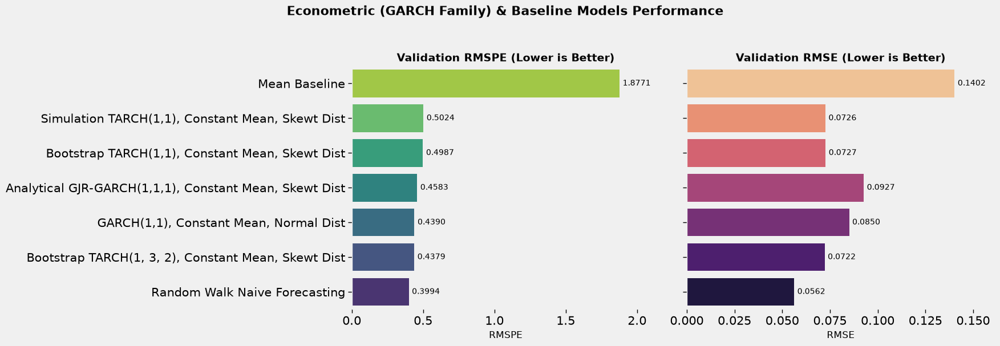

In [1684]:
garch_sorted = perf_df.sort_values(by='Validation RMSPE', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# Left subplot: Validation RMSPE
sns.barplot(
    data=garch_sorted,
    x='Validation RMSPE',
    y='Model',
    palette='viridis_r',
    ax=axes[0]
)
axes[0].set_title('Validation RMSPE (Lower is Better)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('RMSPE', fontsize=12)
axes[0].set_ylabel('')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.4f', padding=4, fontsize=10)
axes[0].set_xlim(0, garch_sorted['Validation RMSPE'].max() * 1.15)

# Right subplot: Validation RMSE
sns.barplot(
    data=garch_sorted,
    x='Validation RMSE',
    y='Model',
    palette='magma_r',
    ax=axes[1]
)
axes[1].set_title('Validation RMSE (Lower is Better)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('RMSE', fontsize=12)
axes[1].set_ylabel('')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.4f', padding=4, fontsize=10)
axes[1].set_xlim(0, garch_sorted['Validation RMSE'].max() * 1.15)

plt.suptitle('Econometric (GARCH Family) & Baseline Models Performance', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [1685]:
# Get the best-performing lookback window for each NN architecture
best_nn = (
    nn_perf_df
    .sort_values('RMSPE')
    .groupby(nn_perf_df['Model'].str.replace(r', n_past=\d+$', '', regex=True), as_index=False)
    .first()
    .rename(columns={'RMSPE': 'Validation RMSPE', 'RMSE': 'Validation RMSE'})
    [['Model', 'Validation RMSPE', 'Validation RMSE']]
)

# Combine with GARCH & Baseline models
final_leaderboard = (
    pd.concat([perf_df, best_nn], ignore_index=True)
    .sort_values(by='Validation RMSPE', ascending=True)
    .reset_index(drop=True)
)

(
    final_leaderboard.style
    .format({'Validation RMSPE': '{:.4f}', 'Validation RMSE': '{:.4f}'})
    .highlight_min(subset=['Validation RMSPE', 'Validation RMSE'], color='#d4edda')
    .set_caption("Final Validation Leaderboard: Econometric (GARCH) vs. Neural Networks")
)

,Model,Validation RMSPE,Validation RMSE
0,Random Walk Naive Forecasting,0.3994,0.0562
1,"Multivariate 3 Bidirect LSTM layers (64/32/16 units) (Layer Normalization), n_past=30",0.4301,0.0711
2,"Bootstrap TARCH(1, 3, 2), Constant Mean, Skewt Dist",0.4379,0.0722
3,"GARCH(1,1), Constant Mean, Normal Dist",0.4390,0.0850
4,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.4583,0.0927
5,"2-Layered Bidirectional LSTMs (32/16 units), n_past=30",0.4779,0.0654
6,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.4987,0.0727
7,"1-Layered LSTM 20 units, n_past=30",0.5017,0.0596
8,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.5024,0.0726
9,"1 Conv1D 2-Layered Bidirectional LSTMs (32/16 units), n_past=30",0.5027,0.0686


## Conclusion & Key Takeaways
In this project, we investigated forecasting the next 7 days' average daily Realized Volatility of **Solana (`SOL-USD`)** over a 5-year horizon (`2021–2025`), comparing traditional econometric time-series models (GARCH family) against deep learning architectures (Fully Connected Networks, Univariate LSTMs, Conv1D-BiLSTMs, and Multivariate Bidirectional LSTMs).

### Key Findings:
1. **Solana's Volatility Structure:** `SOL-USD` exhibits pronounced volatility clustering, heavy tails (leptokurtic return distributions), and asymmetric shock responses—evidenced by extreme historical dislocations during the June 2021 market crah (~0.15 daily RV) and the November–December 2022 FTX contagin (~0.13 daily RV). Modeling residuals with a Skewed Student's $t$ distribution (`skewt`) substantially improved GARCH/TARCH log-likelihoods over normal-distribution assumptions.
2. **Econometric vs. Deep Learning Performance:** Among econometric models, **Bootstrap `TARCH(1, 3, 2)`** performed best on validation data (`0.4379` RMSPE, `0.0722` RMSE). However, incorporating multivariate features (daily returns, trading volume, and realized volatility) into a **3-Layer Bidirectional LSTM (`64/32/16` units with Layer Normalization, `n_past=30`)** outperformed all GARCH-family models (`0.4301` Validation RMSPE, `0.0711` Validation RMSE).
3. **Persistence of Volatility & The Naive Benchmark:** Because 30-day rolling realized volatility is highly persistent over short 7-day horizons, the **Random Walk Naive** forecast (`0.3994` Validation RMSPE) remains a strong benchmark. While the Multivariate Bi-LSTM closely tracks regime shifts and avoids the lag bias seen in simpler networks, out-of-sample crypto volatility remains inherently noisy during sudden macro or ecosystem shocks.

### Future Improvements:
- **Derivatives & On-Chain Features:** Incorporating Solana perpetual funding rates, open interest, implied volatility surfaces (e.g., Deribit SOL options), and on-chain DEX volume/liquidity metrics could provide leading signals before realized volatility spikes.
- **Loss Function Alignment:** Training neural networks directly with a custom asymmetric or quantile-weighted loss function tailored to options trading $P/L$ could better penalize under-predictions ahead of tail-risk events.

# References:

1. Géron, A. (2019). *In Hands-on machine learning with Scikit-Learn & TensorFlow: concepts, tools, and techniques to build intelligent systems.* O'Reilly Media, Inc.

2. Sinclair, E. (2020). *Positional option trading: An advanced guide.* John Wiley &amp; Sons. 

3. https://algotrading101.com/learn/yfinance-guide/ 

4. https://www.coursera.org/learn/tensorflow-sequences-time-series-and-prediction/supplement/DM4fi/convolutional-neural-networks-course

5. https://insights.deribit.com/options-course/

6. https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html 

7. https://www.investopedia.com/terms/v/vix.asp 

8. https://www.hindawi.com/journals/complexity/2021/6647534/ 

9. https://github.com/ritvikmath/Time-Series-Analysis/blob/master/GARCH%20Stock%20Modeling.ipynb

10. https://github.com/ritvikmath/Time-Series-Analysis/blob/master/GARCH%20Model.ipynb

11. https://www.kaggle.com/c/optiver-realized-volatility-prediction 

12. https://www.youtube.com/watch?v=NKHQiN-08S8

13. https://goldinlocks.github.io/ARCH_GARCH-Volatility-Forecasting/ 

14. https://towardsdatascience.com/time-series-analysis-on-multivariate-data-in-tensorflow-2f0591088502 

15. https://deepmind.com/blog/article/wavenet-generative-model-raw-audio 

16. https://github.com/philipperemy/keras-tcn 

17. http://users.metu.edu.tr/ozancan/ARCHGARCHTutorial.html

18. https://towardsdatascience.com/8-commonly-used-pandas-display-options-you-should-know-a832365efa95